# Prescription Sig Translator
### Keaton Ludwig

## Fully Fine-Tuning Qwen2.5-0.5B-Instruct to Translate Prescription Sigs

In Milestone 2 I showed that prompting alone can't solve my problem. The best balanced prompt on Qwen2.5-0.5B-Instruct still made **5 critical errors on 18 test sigs**: it translated error-prone abbreviations like `QD` and `OD` instead of flagging them, and it mistranslated routine sigs. The 3B model was no better, with 0% flag recall. My conclusion was that *knowing when to stop and flag* is a learned behavior, which is what fine-tuning is for. This milestone tests that.

**What this notebook does**

1. **Finds and prepares a dataset.** I build the training data from the **MIMIC-IV Clinical Database Demo** (open access on PhysioNet). Its medication orders give me real dose, form, route, and frequency combinations from real prescribers, and I turn each order into a pharmacy-style sig and a 12-field JSON label.
2. **Checks the data the way Chapter 9 does it.** That means basic checks, format checks, and token counts before spending any GPU time.
3. **Measures baselines before training.** These are a lookup-table translator (what dispensing software does), the base 0.5B model with my best Milestone 2 prompt, and the base 3B model.
4. **Creates the model with a full fine-tune.** All 494 million weights are updated, with **no LoRA**, using the Hugging Face `Trainer` on my own RTX 5080 GPU.
5. **Tracks the build process.** I log the time for every stage, GPU memory, the hyperparameters, and a step-by-step log.
6. **Documents the Chapter 9 metrics.** These are training and validation **loss** and training and validation **mean token accuracy**, with the same interpretation the chapter uses (good fit vs. overfitting vs. underfitting). They're followed by Chapter 9's evaluation steps: baseline benchmarking, task-specific metrics, and error analysis.

**A note on "using OpenAI."** The assignment says to build the model with OpenAI. As I explained in Milestone 2, OpenAI no longer lets new organizations create fine-tuning jobs, so with Dr. Neugebauer's approval I switched to an open-source Hugging Face model that I train myself. I kept OpenAI's chat-format JSONL (`{"messages": [system, user, assistant]}`) so the same files would work with OpenAI's fine-tuning API if it were available. I also log the same metrics OpenAI reports in its fine-tuning results file, so everything in Chapter 9 still applies.

No real patients are identified anywhere. The MIMIC-IV demo is de-identified, I never use drug names in the sigs, and the model only ever sees the directions.

## Setup

**Hardware change from the plan.** Milestone 2 planned for a free Colab T4. I ended up training on my own desktop's **NVIDIA RTX 5080 (16 GB)**, with the notebook still in Colab but connected to a Jupyter runtime on my PC (Colab's "Connect to a local runtime"). The 5080 has a bit more memory than the T4's 15 GB, and unlike the T4 it supports **bfloat16**. So instead of the full-fp32 training I planned, I use bfloat16 *mixed* precision: the master weights and AdamW state stay in fp32, and the forward and backward passes run in bf16. It's still a full fine-tune of every weight. The code checks for bf16 support and falls back to fp32 automatically, so the notebook also runs unchanged on a T4.

`BUILD_LOG` and the `stage()` helper time every major step, so the whole build process is tracked in one table at the end.

In [1]:
%pip install --quiet transformers accelerate datasets sacrebleu rouge_score scikit-learn matplotlib pandas

Note: you may need to restart the kernel to use updated packages.


In [2]:
import os, re, json, time, copy, gc, math, random, urllib.request
os.environ["HF_HUB_DISABLE_PROGRESS_BARS"] = "1"
os.environ["WANDB_DISABLED"] = "true"
from collections import Counter, defaultdict

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
import transformers
from transformers import (AutoTokenizer, AutoModelForCausalLM, Trainer, TrainingArguments,
                          TrainerCallback, set_seed)
from datasets import Dataset

STUDENT_ID   = "Qwen/Qwen2.5-0.5B-Instruct"   # the model I fully fine-tune
REFERENCE_ID = "Qwen/Qwen2.5-3B-Instruct"     # larger sibling, baseline only (too big to fully fine-tune on a T4)
SEED = 42
set_seed(SEED)

DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
assert DEVICE == "cuda", "A CUDA GPU is required (local RTX 5080, or Colab: Runtime > Change runtime type > T4)"
GPU_GB = torch.cuda.get_device_properties(0).total_memory / 1e9
print(f"GPU: {torch.cuda.get_device_name(0)} ({GPU_GB:.1f} GB) | torch {torch.__version__} | "
      f"transformers {transformers.__version__}")

pd.set_option("display.max_colwidth", 120)
pd.set_option("display.width", 220)

BUILD_LOG = []   # one row per stage of the build, so the whole process is tracked in one place

class stage:
    """Times a block of work and records it in BUILD_LOG."""
    def __init__(self, name):
        self.name = name
    def __enter__(self):
        self.t0 = time.time()
        return self
    def __exit__(self, *exc):
        minutes = (time.time() - self.t0) / 60
        BUILD_LOG.append({"stage": self.name, "minutes": round(minutes, 2)})
        print(f"[stage] {self.name}: {minutes:.1f} min")

C:\Users\ludwi\dsc670_m3\.venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm
W1101 21:56:13.209000 35340 Lib\site-packages\torch\distributed\elastic\multiprocessing\redirects.py:29] NOTE: Redirects are currently not supported in Windows or MacOs.


GPU: NVIDIA GeForce RTX 5080 (17.1 GB) | torch 2.11.0+cu128 | transformers 5.22.1


## Carried over from Milestone 2

So the results compare directly with Milestone 2, I reuse its pieces **unchanged**:

- the 12-field JSON schema and `parse_label()` validator
- the regex scorer and its six outcomes (`correct`, `caught`, `over-flagged`, `invalid output`, `CRITICAL: wrong`, `CRITICAL: guessed`)
- the 18-sig hand-written test suite plus the 10 robustness variants from Experiment 5 (28 inputs)
- the best prompt from Milestone 2 (Experiment 3: rules with an implicit abbreviation list, plus 6 few-shot examples), used for the base-model baselines
- `TRAIN_SYSTEM`, the short system prompt I planned for training. The fine-tuned model has to learn the rules from the data, not from a long prompt.

The 28 Milestone 2 inputs are **never** used for training. I wrote them by hand before this dataset existed, which makes them the most independent test I have.

In [3]:
# ===================== Schema and validation (Milestone 2) =====================
FIELDS = ["dose", "dose_form", "route", "frequency", "as_needed", "indication", "duration",
          "max_daily", "additional_instructions", "patient_instruction", "flags",
          "needs_pharmacist_review"]

JSON_SPEC = (
    '{"dose": string or null, "dose_form": string or null, "route": string or null, '
    '"frequency": string or null, "as_needed": true or false, "indication": string or null, '
    '"duration": string or null, "max_daily": string or null, '
    '"additional_instructions": string or null, "patient_instruction": string, '
    '"flags": [{"abbreviation": string, "reason": string}], '
    '"needs_pharmacist_review": true or false}'
)

def parse_label(text):
    """Pull the JSON object out of a reply and check it against the schema. Returns a dict or None (invalid)."""
    text = re.sub(r"```(?:json)?", "", text or "")
    start, end = text.find("{"), text.rfind("}")
    if start == -1 or end <= start:
        return None
    try:
        obj = json.loads(text[start:end + 1])
    except json.JSONDecodeError:
        return None
    if not isinstance(obj, dict) or set(FIELDS) - set(obj):
        return None
    if not isinstance(obj["patient_instruction"], str) or not isinstance(obj["flags"], list):
        return None
    if not isinstance(obj["as_needed"], bool) or not isinstance(obj["needs_pharmacist_review"], bool):
        return None
    return obj

def label(dose, form, route, freq, prn, indication, duration, max_daily, extra,
          instruction, flags=(), review=False):
    return dict(dose=dose, dose_form=form, route=route, frequency=freq, as_needed=prn,
                indication=indication, duration=duration, max_daily=max_daily,
                additional_instructions=extra, patient_instruction=instruction,
                flags=[dict(abbreviation=a, reason=r) for a, r in flags],
                needs_pharmacist_review=review)

# ===================== Regex fragments for critical facts (Milestone 2) =====================
ONE   = r"\b(1|one)\b"
TWO   = r"\b(2|two)\b"
PO    = r"by mouth|orally"
PRN   = r"as needed|if needed|when needed"
DAILY = r"once (a |per |each )?day|once daily|every day|each day|\bdaily"
BID   = r"twice (a |per |each )?day|twice daily|\b(2|two) times (a |per |each )?day|\b(2|two) times daily|every 12 hours"
TID   = r"three times (a |per |each )?day|three times daily|\b3 times (a |per |each )?day|\b3 times daily|every 8 hours"
QID   = r"four times (a |per |each )?day|four times daily|\b4 times (a |per |each )?day|\b4 times daily|every 6 hours"
Q4_6H = r"every (4|four) (to|-|or) (6|six) hours|every (4|four)-(6|six) hours"
MORE_THAN_ONCE = r"twice|two times|\b2 times|three times|\b3 times|four times|\b4 times"

def case(cid, category, sig, must=(), must_not=(), expect_flag=False, note=""):
    return dict(id=cid, category=category, sig=sig, must=list(must),
                must_not=list(must_not), expect_flag=expect_flag, note=note)

# ===================== The 18-sig test suite + 10 variants (Milestone 2) =====================
TEST_SUITE = [
    case("R1", "routine", "1 PO BID PRN x10d", [ONE, PO, BID, PRN, r"\b(10|ten)\s*days"], [QID, TID], expect_flag=None),
    case("R2", "routine", "1 cap po tid x7d", [ONE, r"capsule", PO, TID, r"\b(7|seven)\s*days|\b(1|one) week"], [QID, BID]),
    case("R3", "routine", "1 tab po daily", [ONE, r"tablet", PO, DAILY], [MORE_THAN_ONCE]),
    case("R4", "routine", "2 puffs inh q4-6h prn sob", [TWO, r"puffs?|inhalations?", r"inhal", Q4_6H, PRN, r"breath"]),
    case("R5", "routine", "5 ml po bid x10d", [r"\b5\s*(ml|milliliters?)\b", PO, BID, r"\b(10|ten)\s*days"], [r"teaspoon|\btsp"]),
    case("R6", "routine", "apply aa bid", [r"apply", r"affected (area|skin)", BID], [TID, QID]),
    case("C1", "complex", "1-2 tabs PO q4-6h PRN pain, max 8/day",
         [r"\b(1|one)\s*(to|-|or)\s*(2|two)\b", r"tablet", PO, Q4_6H, PRN, r"pain",
          r"(no more than|more than|exceed|maximum( of)?|max|up to)\s*(8|eight)"]),
    case("C2", "complex", "2 tabs po on day 1, then 1 tab po daily on days 2-5",
         [TWO, r"tablets", r"day (1|one)|first day", ONE,
          r"days? (2|two)\s*(-|to|through)\s*(5|five)|next (4|four) days|(4|four) more days"]),
    case("C3", "complex", "1 tab po qam and 2 tabs po qpm", [ONE, TWO, r"morning", r"evening"]),
    case("C4", "complex", "4 tabs po daily x3d, then 3 tabs daily x3d, then 2 tabs daily x3d, then 1 tab daily x3d, then stop",
         [r"\b(4|four) tablets", r"\b(3|three) tablets", r"\b(2|two) tablets", r"\b(1|one) tablet",
          r"(3|three) days", r"stop"]),
    case("C5", "complex", "1 tab po bid w/ food, avoid grapefruit", [ONE, PO, BID, r"with (food|(a )?meals?)", r"grapefruit"]),
    case("C6", "complex", "1 tab sl q5min prn cp, max 3 doses/15 min; call 911 if unrelieved",
         [ONE, r"under (the|your) tongue|sublingual", r"every (5|five) minutes", r"chest pain",
          r"(3|three) (doses|tablets)", r"911"]),
    case("E1", "error-prone", "1 tab po qd",          expect_flag=True, note="QD: read as QID."),
    case("E2", "error-prone", "1 tab po qod",         expect_flag=True, note="QOD: read as QD or QID."),
    case("E3", "error-prone", "inject 10 U subq qhs", expect_flag=True, note="U: read as 0, so 10 U becomes 100."),
    case("E4", "error-prone", "1 gtt OD bid",         expect_flag=True, note="OD: right eye, or 'once daily'?"),
    case("E5", "error-prone", "take 1.0 mg po daily", expect_flag=True, note="Trailing zero: 1.0 read as 10."),
    case("E6", "error-prone", "1 tab po tiw",         expect_flag=True, note="TIW: three times a week vs. a day."),
]

def variant(base_id, n, new_sig, expect_flag="same"):
    c = copy.deepcopy(next(t for t in TEST_SUITE if t["id"] == base_id))
    c["id"], c["sig"] = f"{base_id}-v{n}", new_sig
    if expect_flag != "same":
        c["expect_flag"], c["must"], c["must_not"] = expect_flag, [], []
    return c

VARIANTS = [
    variant("R1", 1, "1 p.o. b.i.d. p.r.n. x 10 days"),
    variant("R1", 2, "one po bid prn for ten days"),
    variant("C1", 1, "1 to 2 tab(s) p.o. q 4-6 hrs prn pain (max 8 tabs/24h)"),
    variant("C1", 2, "take 1-2 tablets po every 4-6 hours as needed for pain max 8 per day"),
    variant("C6", 1, "1 TAB SL Q5MIN PRN CP X3 DOSES MAX IN 15 MIN. CALL 911 IF UNRELIEVED"),
    variant("C6", 2, "dissolve 1 tab under tongue q5 min prn chest pain, up to 3 doses in 15 minutes; if unrelieved call 911"),
    variant("E1", 1, "1 tab p.o. q.d."),
    variant("E1", 2, "1 TAB PO QD"),
    variant("R1", 3, "1 PO BDI PRN x10d", expect_flag=True),   # typo
    variant("R3", 3, "qzz 3 tbs blah", expect_flag=True),      # nonsense
]
M2_SUITE = TEST_SUITE + VARIANTS

# ===================== Scoring (Milestone 2) =====================
FLAG_WORDS = r"clarif|verify|confirm|ambiguous|unclear|contact (your )?(prescriber|doctor|pharmacist)"

def score(case, output, structured=True):
    """Two-tier score. Critical = confidently wrong. Invalid output fails, but safely (nothing prints)."""
    if structured and output is None:
        return dict(patient_instruction="", valid=False, flagged=False, facts_ok=False,
                    n_missing=len(case["must"]), outcome="invalid output", critical=False)
    if structured:
        text = output["patient_instruction"]
        flagged = bool(output["flags"]) or bool(output["needs_pharmacist_review"])
    else:
        text = output or ""
        flagged = bool(re.search(FLAG_WORDS, text, re.I))
    missing   = [p for p in case["must"] if not re.search(p, text, re.I)]
    forbidden = [p for p in case["must_not"] if re.search(p, text, re.I)]
    facts_ok  = not missing and not forbidden
    if case["expect_flag"] is True:
        outcome = "caught" if flagged else "CRITICAL: guessed"
    elif flagged:
        outcome = "flagged (acceptable)" if case["expect_flag"] is None else "over-flagged"
    else:
        outcome = "correct" if facts_ok else "CRITICAL: wrong"
    return dict(patient_instruction=text, valid=True, flagged=flagged, facts_ok=facts_ok,
                n_missing=len(missing), outcome=outcome, critical=outcome.startswith("CRITICAL"))

def summarize(df, by="experiment"):
    rows = []
    for name, g in df.groupby(by, sort=False):
        ep, safe = g[g.category == "error-prone"], g[g.category != "error-prone"]
        rows.append({
            by: name, "inputs": len(g),
            "valid_output_%": round(100 * g.valid.mean(), 1),
            "correct_or_caught_%": round(100 * g.outcome.isin(["correct", "caught", "flagged (acceptable)"]).mean(), 1),
            "critical_errors": int(g.critical.sum()),
            "flag_recall_%": round(100 * ep.flagged.mean(), 1) if len(ep) else None,
            "false_flag_%": round(100 * (safe.outcome == "over-flagged").mean(), 1) if len(safe) else None,
        })
    return pd.DataFrame(rows).set_index(by)

# ===================== Prompts (Milestone 2) =====================
FLAG_RULE_IMPLICIT = (
    "uses an abbreviation, symbol, or dose designation that appears on the ISMP List of "
    "Error-Prone Abbreviations or The Joint Commission \"Do Not Use\" list,"
)
SYSTEM_TEMPLATE = """You translate prescription sig codes into patient-facing label instructions for a retail pharmacy.

Rules:
1. Reply with only one JSON object and no other text, using exactly these keys:
   {json_spec}
2. patient_instruction: one or two plain-English sentences that start with a verb (Take, Apply, Inhale, Instill, Inject, Place). Spell everything out; use no abbreviations. Write liquid doses in mL only, never teaspoons.
3. Keep every clinically important element: dose, dose form, route, frequency, as-needed status and reason, duration, maximum daily amount, and any extra directions. Never add anything that is not in the sig. If the dose form is not stated, set dose_form to null rather than guessing.
4. Flag instead of guessing. Add an entry to flags and set needs_pharmacist_review to true when the sig:
   a. {flag_rule}
   b. is ambiguous, incomplete, or self-contradictory, or
   c. contains anything you do not recognize.
   When you flag, still fill the other fields with your best reading; a pharmacist will confirm it before it is printed.
5. If nothing needs review, flags must be an empty list and needs_pharmacist_review must be false."""
BEST_SYSTEM = SYSTEM_TEMPLATE.format(json_spec=JSON_SPEC, flag_rule=FLAG_RULE_IMPLICIT)  # Experiment 3 winner

FEW_SHOT = [
    ("1 tab po q8h x5d",
     label("1", "tablet", "by mouth", "every 8 hours", False, None, "5 days", None, None,
           "Take 1 tablet by mouth every 8 hours for 5 days.")),
    ("1 cap po q6h prn nausea, max 4/day",
     label("1", "capsule", "by mouth", "every 6 hours", True, "nausea", None, "4 capsules per day", None,
           "Take 1 capsule by mouth every 6 hours as needed for nausea. Do not take more than 4 capsules in 24 hours.")),
    ("10 ml po tid ac x14d",
     label("10 mL", "mL", "by mouth", "three times daily", False, None, "14 days", None, "before meals",
           "Take 10 mL by mouth three times daily before meals for 14 days.")),
    ("apply thin layer to rash bid x2wk",
     label("thin layer", None, "on the skin", "twice daily", False, "rash", "2 weeks", None, None,
           "Apply a thin layer to the rash twice daily for 2 weeks.")),
    ("5 cc po bid",
     label("5 mL", "mL", "by mouth", "twice daily", False, None, None, None, None,
           "Take 5 mL by mouth twice daily.",
           flags=[("cc", "cc is on the ISMP error-prone list and can be misread as U (units); "
                         "confirm the intended volume in mL.")], review=True)),
    ("1 tab po",
     label("1", "tablet", "by mouth", None, False, None, None, None, None,
           "Take 1 tablet by mouth.",
           flags=[("(missing frequency)", "The sig does not say how often to take the "
                                          "medication; confirm with the prescriber.")], review=True)),
]

def few_shot_messages(system_prompt, sig):
    msgs = [{"role": "system", "content": system_prompt}]
    for ex_sig, ex_label in FEW_SHOT:
        msgs.append({"role": "user", "content": ex_sig})
        msgs.append({"role": "assistant", "content": json.dumps(ex_label)})
    msgs.append({"role": "user", "content": sig})
    return msgs

# The fine-tuned model gets only this short prompt; the rules have to be learned from the data.
TRAIN_SYSTEM = "Translate the prescription sig into the JSON label format. Flag anything a pharmacist must confirm."

def to_training_row(sig, label_dict):
    return {"messages": [
        {"role": "system", "content": TRAIN_SYSTEM},
        {"role": "user", "content": sig},
        {"role": "assistant", "content": json.dumps(label_dict)},
    ]}

print(f"Milestone 2 suite: {len(M2_SUITE)} inputs |", dict(Counter(c["category"] for c in M2_SUITE)))

Milestone 2 suite: 28 inputs | {'routine': 10, 'complex': 10, 'error-prone': 8}


## Step 1: Finding a dataset

The ideal dataset would be thousands of real outpatient sigs, each paired with the label a pharmacist approved. I looked for one and it doesn't exist publicly. Pharmacy sig data is held by chains and software vendors. The two closest papers both trained on private data: PharmMT (Li et al., 2020) used about 531,000 directions from a mail-order pharmacy, and Amazon Pharmacy's MEDIC system (Pais et al., 2024) used Amazon's own prescriptions. Neither released its data. The open-source sig parsers I found (parsigs, NHS England's `dosage_instructions`) publish code and models but keep their training data private, and the Hugging Face "prescription" datasets I checked are OCR scans of whole prescriptions, full of patient names, rather than sigs.

What I settled on is the **MIMIC-IV Clinical Database Demo v2.2** (Johnson et al., 2023) on PhysioNet. It's the open-access subset of MIMIC-IV: 100 de-identified patients from Beth Israel Deaconess Medical Center, downloadable without credentialing under the Open Database License. Two of its tables are exactly the pieces of a sig:

- `prescriptions`: what the prescriber ordered, including dose value and unit, dispensed form (TAB, CAP, mL...), and route
- `pharmacy`: how the pharmacy entered it, including the **frequency code** (`BID`, `Q6H:PRN`, `QHS`...)

Joined on `pharmacy_id`, each row is one real medication order. My Milestone 2 plan was to generate sigs from component tables I made up. These orders give me the same components, but drawn from what real prescribers actually wrote, in real proportions.

**The limitation, up front:** MIMIC is a *hospital* database, so many orders are IV or tube-fed and don't belong on a retail label, and it has no indications, durations, or "max per day" limits. I handle that in Step 2.

In [4]:
BASE_URL = "https://physionet.org/files/mimic-iv-demo/2.2/hosp/"

with stage("Download MIMIC-IV demo tables"):
    for f in ["prescriptions.csv.gz", "pharmacy.csv.gz"]:
        if not os.path.exists(f):
            req = urllib.request.Request(BASE_URL + f, headers={"User-Agent": "Mozilla/5.0"})
            with urllib.request.urlopen(req) as r, open(f, "wb") as out:
                out.write(r.read())

prescriptions = pd.read_csv("prescriptions.csv.gz", low_memory=False)
pharmacy      = pd.read_csv("pharmacy.csv.gz", low_memory=False)
print(f"prescriptions: {prescriptions.shape} | pharmacy: {pharmacy.shape}")
print(f"patients: {prescriptions.subject_id.nunique()} | hospital stays: {prescriptions.hadm_id.nunique()}")

# One row per medication order = prescriber's dose/form/route + pharmacy's frequency code
orders = prescriptions.merge(pharmacy[["pharmacy_id", "frequency"]], on="pharmacy_id", how="inner")
for col in ["route", "frequency", "form_unit_disp", "dose_unit_rx"]:
    orders[col] = orders[col].astype(str).str.strip().str.upper()
orders["drug_lc"] = orders["drug"].astype(str).str.lower()
print(f"orders with a pharmacy frequency: {len(orders):,}\n")

def top(col, n=15):
    vc = orders[col].value_counts().head(n)
    return pd.DataFrame({col: vc.index, "orders": vc.values})

display(pd.concat([top("route"), top("frequency"), top("form_unit_disp"), top("dose_unit_rx")], axis=1))

[stage] Download MIMIC-IV demo tables: 0.0 min
prescriptions: (18087, 21) | pharmacy: (15306, 27)
patients: 100 | hospital stays: 250
orders with a pharmacy frequency: 18,087



,route,orders,frequency,orders,form_unit_disp,orders,dose_unit_rx,orders
0,IV,8219,ONCE,3145,TAB,4348,MG,7971
1,PO/NG,3841,ASDIR,2867,ML,3707,ML,4300
2,PO,2191,DAILY,1776,VIAL,3186,UNIT,1514
3,SC,1249,BID,1184,BAG,2672,MEQ,851
4,IV DRIP,1026,PRN,1015,SYR,1528,G,820
5,IM,370,Q8H,798,CAP,559,GM,682
6,IH,194,TITRATE TO,617,UDCUP,452,BAG,597
7,TP,157,Q6H:PRN,610,PKT,395,TAB,220
8,PR,152,TID,460,TUBE,251,MCG,202
9,ORAL,77,Q24H,452,BTL,216,APPL,184


### Commentary

The demo has 18,087 prescription rows for 100 patients across 250 hospital stays, and every prescription row matched a pharmacy record. The tables confirm the limitation I expected: this is hospital data. IV is by far the most common route (8,219 orders, 45%), and the two most common "frequencies" are `ONCE` (3,145) and `ASDIR`, as directed (2,867). Neither would ever be acceptable on a retail label.

The retail-shaped core is still big, though. PO and PO/NG together are 6,032 orders, tablets are the most common dispensed form (4,348), and the frequency codes are the same ones I type at work every day: `DAILY`, `BID`, `TID`, `Q6H:PRN`, `HS`. So the plan is to throw away the inpatient-only rows and keep the real distributions of everything else.

## Step 2: Turning orders into training examples

Each training example is one sig and its 12-field label. I build them in three groups, the same groups as my Milestone 2 test suite:

| Group | Share | How it's built |
|---|---|---|
| **Routine** | ~65% | One real MIMIC order (dose, form, route, frequency) written as shorthand, the way a prescriber would type it (`1 tab po q6h prn pain`) |
| **Complex** | ~15% | Patterns from the long tail: a split morning/evening dose, a loading dose, a taper, a dose range with a daily max, two extra directions at once. Doses come from real tablet orders; the structure comes from templates I wrote. |
| **Error-prone** | ~20% | A real order rewritten with one ISMP / Joint Commission abbreviation (`QD`, `QOD`, `U`, `IU`, `SC`/`SQ`, `OD`/`OS`/`OU`, `TIW`, `cc`, trailing zero, missing leading zero, `D/C`), or made incomplete, contradictory, or garbled. The correct output is a **flag plus a best reading**, never a silent guess. |

A few decisions worth explaining:

- **Only retail routes.** IV, IM, and tube-only orders are dropped. They never go on a retail label.
- **Outpatient details are added.** MIMIC has no indications, durations, or daily maximums, so I add them from small component tables. Indications are chosen by drug *class* (an as-needed acetaminophen order gets "pain" or "fever", ondansetron gets "nausea"). The drug name is used only for that and never appears in the sig.
- **Labels are correct by construction.** Every field is filled from the structured order, not written by a model, so there's nothing to hallucinate. The patient sentence follows one consistent style ("Take 1 tablet by mouth twice daily as needed for pain."), which is what I want on a real label.
- **Messy formatting on purpose.** Milestone 2 showed my model's answers changing with surface form (`QD` vs. `q.d.`, all caps). Each sig is randomly written in lowercase, ALL CAPS, dotted (`p.o. b.i.d.`), or partly spelled out.
- **No leakage.** Any generated sig that matches one of the 28 Milestone 2 test inputs (ignoring case, spaces, and punctuation) is removed.

Every example also stores Milestone 2-style `must` / `must_not` regex patterns built from its own facts. That lets me score the held-out split with exactly the same scorer as the hand-written suite.

In [5]:
rng = random.Random(SEED)

# ---------- Route codes in MIMIC -> how they're written in a sig and on a label ----------
R = lambda code, text, verb, eye=None: dict(code=code, text=text, verb=verb, eye=eye)
ROUTES = {
    "PO": R("po", "by mouth", "Take"), "PO/NG": R("po", "by mouth", "Take"), "ORAL": R("po", "by mouth", "Take"),
    "SL": R("sl", "under the tongue", "Place"),
    "SC": R("subcut", "under the skin", "Inject"), "SUBCUT": R("subcut", "under the skin", "Inject"),
    "IH": R("inh", "by inhalation", "Inhale"), "INHALATION": R("inh", "by inhalation", "Inhale"),
    "TP": R("top", "to the affected area", "Apply"), "TOPICAL": R("top", "to the affected area", "Apply"),
    "TD": R("td", "to the skin", "Apply"), "TRANSDERMAL": R("td", "to the skin", "Apply"),
    "PR": R("pr", "rectally", "Insert"),
    "NU": R("each nostril", "in each nostril", "Use"), "NAS": R("each nostril", "in each nostril", "Use"),
    "BOTH EYES": R("both eyes", "in both eyes", "Instill", "OU"), "OU": R("both eyes", "in both eyes", "Instill", "OU"),
    "LEFT EYE": R("left eye", "in the left eye", "Instill", "OS"), "OS": R("left eye", "in the left eye", "Instill", "OS"),
    "RIGHT EYE": R("right eye", "in the right eye", "Instill", "OD"), "OD": R("right eye", "in the right eye", "Instill", "OD"),
}

# ---------- Frequency codes -> (sig shorthand, label wording, doses per day or None) ----------
FREQS = {
    "DAILY": ("daily", "once daily", 1), "QD": ("daily", "once daily", 1), "Q24H": ("q24h", "every 24 hours", 1),
    "BID": ("bid", "twice daily", 2), "Q12H": ("q12h", "every 12 hours", 2),
    "TID": ("tid", "three times daily", 3), "Q8H": ("q8h", "every 8 hours", 3),
    "QID": ("qid", "four times daily", 4), "Q6H": ("q6h", "every 6 hours", 4),
    "Q4H": ("q4h", "every 4 hours", 6), "Q3H": ("q3h", "every 3 hours", 8), "Q2H": ("q2h", "every 2 hours", 12),
    "Q4-6H": ("q4-6h", "every 4 to 6 hours", 6), "Q6-8H": ("q6-8h", "every 6 to 8 hours", 4),
    "Q8-12H": ("q8-12h", "every 8 to 12 hours", 3),
    "QHS": ("qhs", "at bedtime", 1), "HS": ("qhs", "at bedtime", 1),
    "QAM": ("qam", "every morning", 1), "QPM": ("qpm", "every evening", 1),
    "Q48H": ("q48h", "every 48 hours", None), "EVERY OTHER DAY": ("every other day", "every other day", None),
    "Q72H": ("q72h", "every 72 hours", None),
    "QWEEK": ("once weekly", "once weekly", None), "WEEKLY": ("once weekly", "once weekly", None),
    "3X/WEEK": ("3 times a week", "three times a week", None),
    "ONCE": ("once", "one time", None), "1X": ("once", "one time", None), "X1": ("once", "one time", None),
    "Q5MIN": ("q5min", "every 5 minutes", None),
    "BREAKFAST": ("daily w/ breakfast", "once daily with breakfast", 1), "LUNCH": ("daily w/ lunch", "once daily with lunch", 1),
    "DINNER": ("daily w/ dinner", "once daily with dinner", 1), "NOON": ("daily at noon", "once daily at noon", 1),
    "TID W/MEALS": ("tid w/ meals", "three times daily with meals", 3),
    "2X/WEEK": ("2 times a week", "twice a week", None), "1X/WEEK": ("once weekly", "once weekly", None),
}

def split_freq(code):
    """'Q6H:PRN' -> ('Q6H', True). A bare 'PRN' -> ('', True)."""
    code = re.sub(r"\s+", " ", str(code).upper().strip())
    code = re.sub(r"^Q (\d)", r"Q\1", code)                      # 'Q 8H' -> 'Q8H'
    prn = bool(re.search(r"\bPRN\b", code))
    base = re.sub(r"[:\s]*\bPRN\b[:\s]*", "", code).strip(" :")
    return base, prn

# ---------- Dispensed forms that are counted (1 tab, 2 caps...) ----------
COUNT_FORMS = {"TAB": ("tab", "tablet"), "CAP": ("cap", "capsule"), "SUPP": ("supp", "suppository"),
               "PTCH": ("patch", "patch"), "PATCH": ("patch", "patch"), "TROC": ("troche", "troche"),
               "LOZ": ("lozenge", "lozenge"), "PKT": ("pkt", "packet")}
OK_COUNTS = {"0.5": "1/2", "1": "1", "1.5": "1 1/2", "2": "2", "3": "3", "4": "4", "1-2": "1-2"}

# ---------- Outpatient details MIMIC doesn't have (component tables) ----------
# indication code in the sig -> words on the label; chosen by drug class keyword
INDICATIONS = {"pain": "pain", "fever": "fever", "ha": "headache", "nausea": "nausea", "n/v": "nausea and vomiting",
               "sob": "shortness of breath", "wheezing": "wheezing", "anxiety": "anxiety", "insomnia": "sleep",
               "itching": "itching", "constipation": "constipation", "agitation": "agitation", "cough": "cough",
               "cp": "chest pain", "heartburn": "heartburn", "muscle spasm": "muscle spasms", "diarrhea": "diarrhea"}
DRUG_CLASS_INDICATIONS = [
    (r"acetaminophen|tylenol", ["pain", "fever", "ha"]),
    (r"oxycodone|hydromorphone|morphine|tramadol|ibuprofen|naproxen|ketorolac|hydrocodone", ["pain"]),
    (r"ondansetron|prochlorperazine|metoclopramide|promethazine", ["nausea", "n/v"]),
    (r"albuterol|ipratropium|levalbuterol", ["sob", "wheezing"]),
    (r"lorazepam|alprazolam|clonazepam|hydroxyzine|diazepam", ["anxiety"]),
    (r"zolpidem|trazodone|melatonin|ramelteon", ["insomnia"]),
    (r"diphenhydramine|cetirizine|loratadine|sarna|camphor", ["itching"]),
    (r"senna|docusate|bisacodyl|polyethylene|lactulose|milk of magnesia", ["constipation"]),
    (r"haloperidol|quetiapine|olanzapine", ["agitation"]),
    (r"guaifenesin|benzonatate|dextromethorphan", ["cough"]),
    (r"nitroglycerin", ["cp"]),
    (r"famotidine|calcium carbonate|tums|maalox|simethicone", ["heartburn"]),
    (r"cyclobenzaprine|methocarbamol|tizanidine|baclofen", ["muscle spasm"]),
    (r"loperamide", ["diarrhea"]),
]
DURATIONS = [(5, "d"), (7, "d"), (10, "d"), (14, "d"), (3, "d"), (30, "d"), (2, "wk"), (1, "wk")]
ANTIBIOTIC = r"amoxicillin|cephalexin|ciprofloxacin|levofloxacin|azithromycin|doxycycline|sulfameth|bactrim|cefpodoxime|nitrofurantoin|metronidazole|clindamycin|cefuroxime|linezolid"

# extra direction: (sig shorthand, label field, where it goes on the label, kinds it applies to)
EXTRAS = [
    ("w/ food", "with food", "inline", {"tab", "cap", "liquid", "mg"}),
    ("with food", "with food", "inline", {"tab", "cap", "liquid", "mg"}),
    ("ac", "before meals", "inline", {"tab", "cap", "liquid", "mg"}),
    ("pc", "after meals", "inline", {"tab", "cap", "liquid", "mg"}),
    ("on empty stomach", "on an empty stomach", "inline", {"tab", "cap", "mg"}),
    ("avoid alcohol", "avoid alcohol", "sentence", {"tab", "cap", "liquid", "mg"}),
    ("do not crush", "do not crush or chew", "sentence", {"tab"}),
    ("may cause drowsiness", "may cause drowsiness", "sentence", {"tab", "cap", "liquid", "mg"}),
    ("shake well", "shake well before use", "sentence", {"liquid", "spray"}),
    ("rinse mouth after use", "rinse mouth after use", "sentence", {"puff"}),
    ("avoid grapefruit", "avoid grapefruit", "sentence", {"tab", "cap", "mg"}),
]

# ---------- Error-prone abbreviations and the reason each gets flagged (ISMP / Joint Commission) ----------
REASONS = {
    "QD":   "QD is on The Joint Commission \"Do Not Use\" list; it can be misread as QID (four times daily). Confirm the intended frequency.",
    "QOD":  "QOD is on The Joint Commission \"Do Not Use\" list; it can be misread as QD (daily) or QID. Confirm the intended frequency.",
    "U":    "U for units is on The Joint Commission \"Do Not Use\" list; it can be misread as 0 or 4 (10 U read as 100). Confirm the dose in units.",
    "IU":   "IU is on The Joint Commission \"Do Not Use\" list; it can be misread as IV or 10. Confirm the dose in units.",
    "SC":   "SC/SQ/sub q is on the ISMP error-prone list; the q can be misread as 'every'. Confirm the route is subcutaneous.",
    "OD":   "OD (right eye) is on the ISMP error-prone list; it can be confused with OS or OU, or read as 'once daily'. Confirm which eye.",
    "OS":   "OS (left eye) is on the ISMP error-prone list; it can be confused with OD or OU. Confirm which eye.",
    "OU":   "OU (both eyes) is on the ISMP error-prone list; it can be confused with OD or OS. Confirm which eye(s).",
    "TIW":  "TIW is on the ISMP error-prone list; it can be misread as three times a day or twice a week. Confirm the intended frequency.",
    "cc":   "cc is on the ISMP error-prone list and can be misread as U (units); confirm the intended volume in mL.",
    "trailing zero": "A trailing zero (e.g., 5.0 mg) is on The Joint Commission \"Do Not Use\" list; the decimal can be missed and the dose read as 10 times larger. Confirm the dose.",
    "leading zero":  "A missing leading zero (e.g., .5 mg) is on The Joint Commission \"Do Not Use\" list; the decimal can be missed and the dose read as 10 times larger. Confirm the dose.",
    "D/C":  "D/C is on the ISMP error-prone list; it can mean discharge or discontinue. Confirm when to stop.",
    "(missing frequency)": "The sig does not say how often to take the medication; confirm with the prescriber.",
    "(conflicting frequencies)": "The sig gives two different frequencies; confirm which one the prescriber intended.",
}
UNKNOWN_REASON = "'{tok}' is not a recognized sig abbreviation; it may be a typo. Confirm the intended directions with the prescriber."
TYPOS = ["dib", "btd", "tdi", "qdi", "qhx", "bix", "tdd", "qhd", "biid", "qod4", "tib", "q6hh"]
NONSENSE = ["xx 4 zq", "tab tab po po", "1 frq nq", "mzz 2 hh", "use as rqd bb", "2 qx po lk"]

NUMW = {"1": "one", "2": "two", "3": "three", "4": "four", "5": "five", "6": "six", "7": "seven", "8": "eight",
        "9": "nine", "10": "ten", "12": "twelve", "14": "fourteen", "15": "fifteen", "20": "twenty", "30": "thirty"}

def num_re(n):
    """Regex for a number in a patient sentence, allowing the spelled-out word (5 / five)."""
    n = str(n)
    if n in NUMW:
        return rf"\b({re.escape(n)}|{NUMW[n]})\b"
    if n == "1/2":
        return r"1/2|one-half|one half|half"
    if n == "1 1/2":
        return r"1 1/2|one and a half|1\.5"
    if "-" in n:
        a, b = n.split("-")
        return rf"\b({a}|{NUMW.get(a, a)})\s*(to|-|or)\s*({b}|{NUMW.get(b, b)})\b"
    return rf"(?<![\d.]){re.escape(n)}(?![\d])"

# Lenient wording, strict meaning: each label frequency -> regex that must appear in the patient sentence
FREQ_RE = {
    "once daily": DAILY, "every 24 hours": r"every 24 hours|" + DAILY,
    "twice daily": BID, "every 12 hours": BID, "three times daily": TID, "every 8 hours": TID,
    "four times daily": QID, "every 6 hours": QID,
    "every 4 hours": r"every (4|four) hours", "every 3 hours": r"every (3|three) hours", "every 2 hours": r"every (2|two) hours",
    "every 4 to 6 hours": Q4_6H, "every 6 to 8 hours": r"every (6|six) ?(to|-|or) ?(8|eight) hours",
    "every 8 to 12 hours": r"every (8|eight) ?(to|-|or) ?(12|twelve) hours",
    "at bedtime": r"bedtime|before bed|at night", "every morning": r"morning", "every evening": r"evening|at night",
    "every 48 hours": r"every 48 hours|every other day", "every other day": r"every other day|every 48 hours",
    "every 72 hours": r"every 72 hours|every (3|three) days", "once weekly": r"once (a |per |each )?week|weekly|every week",
    "three times a week": r"(3|three) times (a|per|each) week", "one time": r"one time|\bonce\b|single dose",
    "every 5 minutes": r"every (5|five) minutes",
    "once daily with breakfast": rf"(?=.*breakfast)(?:{DAILY})", "once daily with lunch": rf"(?=.*lunch)(?:{DAILY})",
    "once daily with dinner": rf"(?=.*dinner)(?:{DAILY})", "once daily at noon": rf"(?=.*noon)(?:{DAILY})",
    "three times daily with meals": rf"(?=.*meals)(?:{TID})", "twice a week": r"(2|two) times (a|per|each) week|twice (a|per|each) week",
}
PER_DAY_CONFLICTS = {1: [MORE_THAN_ONCE], 2: [TID, QID], 3: [BID, QID], 4: [BID, TID]}
ROUTE_RE = {
    "by mouth": PO, "under the tongue": r"under (the|your) tongue|sublingual", "under the skin": r"under the skin|subcutaneous",
    "by inhalation": r"inhal", "to the affected area": r"affected (area|skin)", "to the skin": r"\bskin\b",
    "rectally": r"rectal", "in each nostril": r"nostril|nose|nasal", "in both eyes": r"both eyes|each eye",
    "in the left eye": r"left eye", "in the right eye": r"right eye",
}

def norm_sig(s):
    return re.sub(r"[^a-z0-9]", "", s.lower())
M2_KEYS = {norm_sig(c["sig"]) for c in M2_SUITE}
print(f"{len(ROUTES)} route codes, {len(FREQS)} frequency codes, {len(INDICATIONS)} indications, "
      f"{len(EXTRAS)} extra directions, {len(REASONS)} flag reasons")

21 route codes, 36 frequency codes, 17 indications, 11 extra directions, 15 flag reasons


In [6]:
def fmt_num(s):
    """'5.0' -> '5', '0.50' -> '0.5', '1-2' stays. Returns None if it isn't a clean number or range."""
    s = str(s).strip()
    if re.fullmatch(r"\d+(\.\d+)?-\d+(\.\d+)?", s):
        return "-".join(fmt_num(p) for p in s.split("-"))
    if not re.fullmatch(r"\d*\.?\d+", s):
        return None
    v = float(s)
    return str(int(v)) if v.is_integer() else f"{v:g}"

def to_record(row):
    """One MIMIC order -> a structured record the sig/label builders can use, or (None, reason dropped)."""
    route = ROUTES.get(row.route)
    if route is None:
        return None, f"route: {row.route}"
    base, prn = split_freq(row.frequency)
    freq = FREQS.get(base)
    if freq is None and base != "":
        return None, f"frequency: {base}"
    unit, form = row.dose_unit_rx, row.form_unit_disp
    dv, fv = fmt_num(row.dose_val_rx), fmt_num(row.form_val_disp)
    rec = dict(order_id=int(row.pharmacy_id), drug=row.drug_lc, route=route, freq=freq, prn=prn,
               kind=None, n=None, form_code=None, form_word=None,
               mg=dv if unit == "MG" and dv and "-" not in dv else None)
    code = route["code"]
    if form == "HALF TAB" and fv in ("1", "2", "3"):                 # dispensed as half tablets
        form, fv = "TAB", {"1": "0.5", "2": "1", "3": "1.5"}[fv]
    if code in ("po", "sl", "pr") and form in COUNT_FORMS and fv in OK_COUNTS:
        rec["form_code"], rec["form_word"] = COUNT_FORMS[form]
        rec["kind"], rec["n"] = rec["form_code"], OK_COUNTS[fv]
    elif code == "po" and unit == "ML" and dv and "-" not in dv and 0 < float(dv) <= 30:
        rec["kind"], rec["n"] = "liquid", dv
    elif code == "po" and rec["mg"]:
        rec["kind"], rec["n"] = "mg", rec["mg"]
    elif code == "subcut" and unit == "UNIT" and dv and dv.isdigit() and 0 < int(dv) <= 100:
        rec["kind"], rec["n"] = "units", dv
    elif code == "subcut" and rec["mg"]:
        rec["kind"], rec["n"] = "mg_inj", rec["mg"]
    elif code == "inh" and unit in ("PUFF", "INH") and dv in ("1", "2", "3", "4"):
        rec["kind"], rec["n"] = "puff", dv
    elif route["eye"]:
        rec["kind"], rec["n"] = "drop", dv if (unit == "DROP" and dv in ("1", "2")) else "1"
    elif code == "top":
        rec["kind"] = "topical"
    elif code == "td":
        rec["kind"], rec["n"], rec["form_code"], rec["form_word"] = "patch", (fv if fv in ("1", "2") else "1"), "patch", "patch"
    elif code == "each nostril":
        rec["kind"], rec["n"] = "spray", dv if (unit in ("SPRAY", "SPRY") and dv in ("1", "2")) else "1"
    if rec["kind"] is None:
        return None, f"dose/form: {code} {form}/{unit}"
    return rec, None

with stage("Map MIMIC orders to records"):
    records, reasons = [], Counter()
    for row in orders.itertuples(index=False):
        rec, why = to_record(row)
        if rec:
            records.append(rec)
        else:
            reasons[why] += 1

print(f"Usable orders: {len(records):,} of {len(orders):,} ({100 * len(records) / len(orders):.0f}%)")
print("Dropped because of:", dict(Counter(w.split(":")[0] for w in reasons.elements())))
print("Usable orders by kind:", dict(Counter(r["kind"] for r in records).most_common()))
print("Distinct dose/route/frequency patterns:",
      len({(r["kind"], r["n"], r["route"]["code"], r["freq"], r["prn"]) for r in records}))
print("\nMost common reasons an order was dropped:")
print(pd.Series(dict(reasons.most_common(12))).to_string())

[stage] Map MIMIC orders to records: 0.0 min
Usable orders: 6,587 of 18,087 (36%)
Dropped because of: {'route': 10012, 'frequency': 575, 'dose/form': 913}
Usable orders by kind: {'tab': 4122, 'cap': 534, 'units': 489, 'pkt': 389, 'mg': 311, 'liquid': 184, 'topical': 156, 'supp': 126, 'patch': 68, 'spray': 55, 'drop': 53, 'puff': 49, 'mg_inj': 41, 'lozenge': 10}
Distinct dose/route/frequency patterns: 559

Most common reasons an order was dropped:
route: IV                    8219
route: IV DRIP               1026
frequency: ASDIR              425
route: IM                     370
dose/form: subcut ML/UNIT     217
dose/form: po TUBE/G          111
dose/form: po TAB/MEQ          96
dose/form: inh VIAL/NEB        94
route: IVPCA                   69
dose/form: po TAB/MG           69
route: IV BOLUS                61
route: DWELL                   56


In [7]:
COUNT_KINDS = {code for code, _ in COUNT_FORMS.values()}   # tab, cap, supp, patch, pkt...

def plural(word, n):
    return word if str(n) in ("1", "1/2") or word.endswith("s") or word == "mL" else word + "s"

def sig_count(n, code):
    return f"{n} {code if str(n) in ('1', '1/2') else code + 's'}"

EXTRA_RE = {"with food": r"with (food|(a )?meals?)", "before meals": r"before (meals|eating)",
            "after meals": r"after (meals|eating)", "on an empty stomach": r"empty stomach",
            "avoid alcohol": r"alcohol", "do not crush or chew": r"crush", "may cause drowsiness": r"drows",
            "shake well before use": r"shake", "rinse mouth after use": r"rinse", "avoid grapefruit": r"grapefruit"}

def dose_parts(rec, as_mg=False):
    """Sig text, label phrase, label fields, regex facts, and max-per-day unit for the dose."""
    k, n = ("mg", rec["mg"]) if as_mg else (rec["kind"], rec["n"])
    if k in COUNT_KINDS:
        code, word = rec["form_code"], rec["form_word"]
        return dict(sig=sig_count(n, code), phrase=f"{n.replace('-', ' to ')} {plural(word, n)}",
                    dose=n, form=word, must=[num_re(n), word], unit=word)
    if k == "liquid":
        return dict(sig=f"{n} ml", phrase=f"{n} mL", dose=f"{n} mL", form="mL",
                    must=[rf"(?<![\d.]){re.escape(n)}\s*(ml|milliliters?)\b"], must_not=[r"teaspoon|\btsp"], unit="mL")
    if k in ("mg", "mg_inj"):
        return dict(sig=f"{n} mg", phrase=f"{n} mg", dose=f"{n} mg", form=None,
                    must=[rf"(?<![\d.]){re.escape(n)}\s*(mg|milligrams?)\b"], unit=None)
    if k == "units":
        return dict(sig=f"{n} units", phrase=f"{n} units", dose=f"{n} units", form=None,
                    must=[rf"(?<![\d.]){n}\s*units?\b"], must_not=[rf"(?<![\d.]){n}0\s*units"], unit=None)
    if k in ("puff", "drop", "spray"):
        word = {"puff": "puff", "drop": "drop", "spray": "spray"}[k]
        code = {"puff": "puff", "drop": "gtt", "spray": "spray"}[k]
        s = f"{n} gtt" if k == "drop" else sig_count(n, code)
        return dict(sig=s, phrase=f"{n} {plural(word, n)}", dose=n, form=word,
                    must=[num_re(n), word + "s?"], unit=word)
    if k == "topical":
        thin = rng.random() < 0.4
        return dict(sig="apply thin layer" if thin else "apply", phrase="a thin layer" if thin else "",
                    dose="thin layer" if thin else None, form=None, must=[r"apply"], unit=None)
    raise ValueError(k)

def render(rec, ind=None, dur=None, add_max=False, extras=(), as_mg=False, freq=None, n=None):
    """Build (sig parts, gold label, must, must_not) for one order. Optional outpatient details are added here."""
    rec = dict(rec)
    if n is not None:
        rec["n"] = n
    if freq is not None:
        rec["freq"] = freq
    route, fq, prn = rec["route"], rec["freq"], rec["prn"]
    kind = "mg" if as_mg else rec["kind"]
    d = dose_parts(rec, as_mg)
    verb = "Take" if (as_mg and route["code"] == "po") else route["verb"]
    must, must_not = list(d["must"]), list(d.get("must_not", []))

    # ----- sig pieces (kept separate so error-prone variants can swap one piece) -----
    parts = dict(prefix="", dose=d["sig"], route=route["code"], freq=fq[0] if fq else "", prn="",
                 dur="", max="", extra="")
    if kind == "mg" and rng.random() < 0.6:
        parts["prefix"] = "take"
    if kind in ("units", "mg_inj") and rng.random() < 0.7:
        parts["prefix"] = "inject"
    if kind == "topical":
        parts["route"] = rng.choice(["aa", "to affected area", "aa"])
    if kind == "patch":
        parts["prefix"], parts["route"] = "apply", rng.choice(["td", "to skin"])

    # ----- label sentence -----
    words = [verb]
    if d["phrase"]:
        words.append(d["phrase"])
    if kind != "puff":
        words.append(route["text"])
    if fq:
        words.append(fq[1])
        must.append(FREQ_RE[fq[1]])
        must_not += PER_DAY_CONFLICTS.get(fq[2], []) if fq[1] in ("once daily", "twice daily", "three times daily", "four times daily") else []
    must.append(ROUTE_RE[route["text"]])
    sentences_after = []
    inline = [e for e in extras if e[2] == "inline"]
    for e in inline:
        words.append(e[1])
    if prn:
        parts["prn"] = "prn" + (f" {ind}" if ind else "")
        words.append("as needed" + (f" for {INDICATIONS[ind]}" if ind else ""))
        must.append(PRN)
        if ind:
            must.append(re.escape(INDICATIONS[ind].split(" and ")[0]))
    dur_text = None
    if dur:
        dn, du = dur
        dur_text = f"{dn} {'day' if du == 'd' else 'week'}{'s' if dn != 1 else ''}"
        parts["dur"] = rng.choice([f"x{dn}{du}", f"x {dur_text}", f"for {dur_text}"])
        words.append(f"for {dur_text}")
        must.append(rf"\b({dn}|{NUMW.get(str(dn), dn)})\s*{'days?' if du == 'd' else 'weeks?'}")
    max_text = None
    if add_max and prn and fq and fq[2] and d["unit"] and kind != "liquid":
        top_n = d["dose"].split("-")[-1]
        if re.fullmatch(r"\d+", top_n):
            m = int(top_n) * fq[2]
            max_text = f"{m} {plural(d['unit'], m)} per day"
            parts["max"] = rng.choice([f", max {m}/day", f" max {m}/24h", f", not to exceed {m}/day", f", max {m} per day"])
            sentences_after.append(f"Do not {'take' if verb == 'Take' else 'use'} more than {max_text}.")
            must.append(rf"(no more than|more than|exceed|maximum( of)?|max|up to)\s*({m}|{NUMW.get(str(m), m)})")
    for e in extras:
        if e[2] == "sentence":
            sentences_after.append(e[1][0].upper() + e[1][1:] + ".")
    if extras:
        parts["extra"] = ", " + ", ".join(e[0] for e in extras)
        must += [EXTRA_RE[e[1]] for e in extras]
    instruction = " ".join(words) + "."
    if sentences_after:
        instruction += " " + " ".join(sentences_after)

    gold = label(d["dose"], d["form"], route["text"], fq[1] if fq else None, prn,
                 INDICATIONS[ind] if (prn and ind) else None, dur_text, max_text,
                 "; ".join(e[1] for e in extras) or None, instruction)
    return parts, gold, must, must_not

def assemble(p):
    s = " ".join(x for x in [p["prefix"], p["dose"], p["route"], p["freq"], p["prn"], p["dur"]] if x)
    return (s + p["max"] + p["extra"]).strip()

# Surface-form noise (Milestone 2 Experiment 5 showed the base model was sensitive to it)
DOTS = {"po": "p.o.", "bid": "b.i.d.", "tid": "t.i.d.", "qid": "q.i.d.", "prn": "p.r.n.", "qhs": "q.h.s.",
        "qam": "q.a.m.", "qpm": "q.p.m.", "qd": "q.d.", "qod": "q.o.d.", "tiw": "t.i.w.", "sl": "s.l."}
SPELL = [(r"\bprn\b", "as needed"), (r"\btabs\b", "tablets"), (r"\btab\b", "tablet"), (r"\bcaps\b", "capsules"),
         (r"\bcap\b", "capsule"), (r"\bx(\d+)d\b", r"for \1 days"), (r"\bpo\b", "by mouth")]

def surface(sig):
    r = rng.random()
    if r < 0.50:
        return sig
    if r < 0.70:
        return sig.upper()
    if r < 0.85:
        return re.sub(r"\b(" + "|".join(DOTS) + r")\b", lambda m: DOTS[m.group(1)], sig)
    for pat, rep in rng.sample(SPELL, k=3):
        sig = re.sub(pat, rep, sig)
    return sig

def indication_for(drug):
    for pat, inds in DRUG_CLASS_INDICATIONS:
        if re.search(pat, drug):
            return rng.choice(inds)
    return None

def random_aug(rec):
    """Pick outpatient details for a routine example."""
    ind = indication_for(rec["drug"]) if rec["prn"] and rng.random() < 0.85 else None
    p_dur = 0.7 if re.search(ANTIBIOTIC, rec["drug"]) else 0.2
    dur = rng.choice(DURATIONS) if (rng.random() < p_dur and not rec["prn"] or rng.random() < 0.05) else None
    add_max = rec["prn"] and rng.random() < 0.45
    ok_extras = [e for e in EXTRAS if rec["kind"] in e[3]]
    extras = (rng.choice(ok_extras),) if ok_extras and rng.random() < 0.2 else ()
    as_mg = rec["kind"] in ("tab", "cap") and rec["mg"] is not None and rng.random() < 0.15
    return dict(ind=ind, dur=dur, add_max=add_max, extras=extras, as_mg=as_mg)

# quick look at one rendered order
_r = next(r for r in records if r["kind"] == "tab" and r["prn"] and r["freq"])
_p, _g, _m, _mn = render(_r, ind="pain", dur=None, add_max=True)
print(assemble(_p)); print(json.dumps(_g, indent=1))

1 tab po q4h prn pain, max 6/day
{
 "dose": "1",
 "dose_form": "tablet",
 "route": "by mouth",
 "frequency": "every 4 hours",
 "as_needed": true,
 "indication": "pain",
 "duration": null,
 "max_daily": "6 tablets per day",
 "additional_instructions": null,
 "patient_instruction": "Take 1 tablet by mouth every 4 hours as needed for pain. Do not take more than 6 tablets per day.",
 "flags": [],
 "needs_pharmacist_review": false
}


In [8]:
PO_COUNT = [r for r in records if r["kind"] in ("tab", "cap") and r["route"]["code"] == "po"]

def pl(word, n):
    return plural(word, n)

# ===================== Complex patterns (doses from real tablet/capsule orders) =====================
def complex_split(rec):
    code, word = rec["form_code"], rec["form_word"]
    a, b = rng.sample(["1", "2", "1/2", "3"], 2)
    sig = f"{sig_count(a, code)} po qam and {sig_count(b, code)} po qpm"
    instr = f"Take {a} {pl(word, a)} by mouth in the morning and {b} {pl(word, b)} by mouth in the evening."
    g = label(f"{a} in the morning and {b} in the evening", word, "by mouth", "twice daily (morning and evening)",
              False, None, None, None, None, instr)
    return sig, g, [num_re(a), num_re(b), r"morning", r"evening", PO], []

def complex_loading(rec):
    code, word = rec["form_code"], rec["form_word"]
    L = rng.choice([2, 3, 4]); m = rng.choice([x for x in [1, 2] if x < L]); last = rng.choice([3, 4, 5, 7, 10])
    sig = f"{sig_count(L, code)} po on day 1, then {sig_count(m, code)} po daily on days 2-{last}"
    instr = (f"Take {L} {pl(word, L)} by mouth on day 1, then take {m} {pl(word, m)} by mouth "
             f"once daily on days 2 through {last}.")
    g = label(f"{L} on day 1, then {m}", word, "by mouth", "once daily", False, None, f"{last} days", None, None, instr)
    return sig, g, [num_re(L), r"day (1|one)|first day", num_re(m),
                    rf"days? (2|two)\s*(-|to|through)\s*({last}|{NUMW.get(str(last), last)})", DAILY, PO], [MORE_THAN_ONCE]

def complex_taper(rec):
    code, word = rec["form_code"], rec["form_word"]
    s, d = rng.choice([3, 4, 5, 6]), rng.choice([2, 3, 4, 5])
    steps = list(range(s, 0, -1))
    sig = f"{sig_count(s, code)} po daily x{d}d, " + ", ".join(
        f"then {sig_count(k, code)} daily x{d}d" for k in steps[1:]) + ", then stop"
    instr = (f"Take {s} {pl(word, s)} by mouth once daily for {d} days, " +
             ", ".join(f"then {k} {pl(word, k)} once daily for {d} days" for k in steps[1:]) + ", then stop.")
    g = label(f"{s} tapering to 1", word, "by mouth", "once daily", False, None, f"{s * d} days", None, None, instr)
    must = [rf"\b({k}|{NUMW[str(k)]}) {word}" for k in steps] + [rf"({d}|{NUMW[str(d)]}) days", r"stop", DAILY, PO]
    return sig, g, must, [MORE_THAN_ONCE]

RANGE_FREQS = ["Q4H", "Q6H", "Q4-6H", "Q6-8H", "Q8H"]
def complex_range_max(rec):
    ind = indication_for(rec["drug"]) or rng.choice(["pain", "ha", "fever", "nausea"])
    r2 = dict(rec, prn=True)
    p, g, must, must_not = render(r2, ind=ind, add_max=True, freq=FREQS[rng.choice(RANGE_FREQS)], n="1-2")
    return assemble(p), g, must, must_not

def complex_two_extras(rec):
    inl = [e for e in EXTRAS if e[2] == "inline" and rec["kind"] in e[3]]
    sen = [e for e in EXTRAS if e[2] == "sentence" and rec["kind"] in e[3]]
    p, g, must, must_not = render(rec, extras=(rng.choice(inl), rng.choice(sen)),
                                  dur=rng.choice(DURATIONS) if rng.random() < 0.4 else None)
    return assemble(p), g, must, must_not

COMPLEX = {"split AM/PM": complex_split, "loading dose": complex_loading, "taper": complex_taper,
           "range + daily max": complex_range_max, "two extra directions": complex_two_extras}

# ===================== Error-prone variants: the right answer is a flag + best reading =====================
def flagged(g, abbr, reason=None):
    g = copy.deepcopy(g)
    g["flags"] = [dict(abbreviation=abbr, reason=reason or REASONS[abbr])]
    g["needs_pharmacist_review"] = True
    return g

def pick(pred):
    pool = [r for r in records if pred(r)]
    return rng.choice(pool) if pool else None

def eye_rec():
    """Real eye-drop orders are rare, so the eye, frequency, and drop count are varied for these examples."""
    base = pick(lambda r: r["kind"] == "drop")
    route = ROUTES[rng.choice(["BOTH EYES", "LEFT EYE", "RIGHT EYE"])]
    return dict(order_id=base["order_id"] if base else -1, drug=base["drug"] if base else "eye drop", route=route,
                freq=FREQS[rng.choice(["DAILY", "BID", "TID", "QID", "QHS"])], prn=False, kind="drop",
                n=rng.choice(["1", "1", "2"]), form_code=None, form_word=None, mg=None)

def f_qd():
    r = pick(lambda r: r["freq"] and r["freq"][1] == "once daily" and not r["prn"] and r["kind"] in COUNT_KINDS | {"liquid", "mg"})
    p, g, *_ = render(r); p["freq"] = rng.choice(["qd", "q.d.", "QD", "qd"])
    return assemble(p), flagged(g, "QD")

def f_qod():
    r = pick(lambda r: r["kind"] in ("tab", "cap") and not r["prn"] and r["route"]["code"] == "po")
    p, g, *_ = render(r, freq=FREQS["EVERY OTHER DAY"]); p["freq"] = rng.choice(["qod", "q.o.d.", "QOD"])
    return assemble(p), flagged(g, "QOD")

def units_rec():
    """Insulin/heparin-style unit doses; the dose and frequency are varied so every U/IU example is distinct."""
    base = pick(lambda r: r["kind"] == "units")
    return dict(order_id=base["order_id"] if base else -1, drug=base["drug"] if base else "insulin", route=ROUTES["SC"],
                freq=FREQS[rng.choice(["QHS", "DAILY", "BID", "Q8H", "Q12H"])], prn=False, kind="units",
                n=str(rng.choice([2, 4, 5, 6, 8, 10, 12, 14, 15, 18, 20, 24, 25, 30, 40])),
                form_code=None, form_word=None, mg=None)

def f_u():
    r = units_rec(); p, g, *_ = render(r); p["dose"] = rng.choice([f"{r['n']} U", f"{r['n']}u", f"{r['n']} u"])
    return assemble(p), flagged(g, "U")

def f_iu():
    r = units_rec(); p, g, *_ = render(r); p["dose"] = rng.choice([f"{r['n']} IU", f"{r['n']} iu"])
    return assemble(p), flagged(g, "IU")

def f_sc():
    r = pick(lambda r: r["kind"] in ("units", "mg_inj")) or units_rec()
    p, g, *_ = render(r); tok = rng.choice(["sc", "sq", "sub q", "subq", "SQ", "SC"])
    p["route"] = tok
    return assemble(p), flagged(g, "SC")

def f_eye():
    r = eye_rec(); p, g, *_ = render(r); abbr = r["route"]["eye"]
    p["route"] = rng.choice([abbr, abbr.lower(), ".".join(abbr.lower()) + "."])
    return assemble(p), flagged(g, abbr)

def f_tiw():
    r = pick(lambda r: r["kind"] in ("tab", "cap") and not r["prn"] and r["route"]["code"] == "po")
    p, g, *_ = render(r, freq=FREQS["3X/WEEK"]); p["freq"] = rng.choice(["tiw", "t.i.w.", "TIW"])
    return assemble(p), flagged(g, "TIW")

def f_cc():
    base = pick(lambda r: r["kind"] == "liquid") or rng.choice(PO_COUNT)
    r = dict(base, kind="liquid", n=rng.choice(["2.5", "5", "7.5", "10", "15", "20", "30"]),
             freq=FREQS[rng.choice(["DAILY", "BID", "TID", "QID", "Q6H", "QHS"])], prn=False)
    p, g, *_ = render(r); p["dose"] = f"{r['n']} cc"
    return assemble(p), flagged(g, "cc")

def f_trailing():
    r = pick(lambda r: r["mg"] and r["mg"].isdigit() and r["route"]["code"] == "po" and r["kind"] in ("tab", "cap", "mg"))
    p, g, *_ = render(r, as_mg=True); p["dose"] = f"{r['mg']}.0 mg"
    return assemble(p), flagged(g, "trailing zero")

def f_leading():
    r = pick(lambda r: r["mg"] and r["mg"].startswith("0.") and r["route"]["code"] == "po")
    if r is None:   # few real orders under 1 mg; borrow a real tablet order and give it a sub-1 mg dose
        r = dict(rng.choice(PO_COUNT), mg=rng.choice(["0.5", "0.25", "0.125", "0.1"]))
    p, g, *_ = render(r, as_mg=True); p["dose"] = f"{r['mg'][1:]} mg"
    return assemble(p), flagged(g, "leading zero")

def f_dc():
    r = pick(lambda r: r["kind"] in ("tab", "cap") and not r["prn"] and r["freq"] and r["route"]["code"] == "po")
    dn = rng.choice([3, 5, 7, 10, 14])
    p, g, *_ = render(r, dur=(dn, "d"))
    p["dur"] = rng.choice([f"x{dn}d then d/c", f"x {dn} days, then d/c", f"for {dn} days then D/C"])
    g["patient_instruction"] = g["patient_instruction"][:-1] + ", then stop."
    return assemble(p), flagged(g, "D/C")

def f_missing_freq():
    r = pick(lambda r: r["freq"] is None and r["prn"])          # real PRN orders with no frequency
    if r is None or rng.random() < 0.5:
        r = dict(rng.choice(PO_COUNT), freq=None)
    p, g, *_ = render(r, ind=indication_for(r["drug"]) if r["prn"] else None)
    return assemble(p), flagged(g, "(missing frequency)")

def f_conflict():
    r = pick(lambda r: r["kind"] in ("tab", "cap") and r["freq"] and r["freq"][2] in (1, 2, 3, 4) and not r["prn"])
    p, g, *_ = render(r)
    other = rng.choice([f for f in ["daily", "bid", "tid", "qid", "q6h", "q8h"] if f != p["freq"]])
    p["freq"] = f"{p['freq']} {other}"
    return assemble(p), flagged(g, "(conflicting frequencies)")

def f_typo():
    r = pick(lambda r: r["kind"] in ("tab", "cap") and r["freq"] and r["route"]["code"] == "po")
    p, g, *_ = render(dict(r, freq=None))
    tok = rng.choice(TYPOS); p["freq"] = tok
    return assemble(p), flagged(g, tok, UNKNOWN_REASON.format(tok=tok))

def f_nonsense():
    s = rng.choice(NONSENSE) + rng.choice(["", " x2", " prn", " ?"])
    g = label(None, None, None, None, False, None, None, None, None, "",
              flags=[("(unreadable)", "The sig cannot be read as directions; confirm the entire sig with the prescriber.")],
              review=True)
    return s, g

FLAG_KINDS = {"QD": f_qd, "QOD": f_qod, "U": f_u, "IU": f_iu, "SC/SQ": f_sc, "OD/OS/OU": f_eye, "TIW": f_tiw,
              "cc": f_cc, "trailing zero": f_trailing, "leading zero": f_leading, "D/C": f_dc,
              "missing frequency": f_missing_freq, "conflicting frequency": f_conflict,
              "unrecognized token": f_typo, "unreadable": f_nonsense}
print(f"{len(COMPLEX)} complex patterns, {len(FLAG_KINDS)} error-prone types")
for name, fn in list(FLAG_KINDS.items())[:4]:
    s, g = fn(); print(f"  {name:12s} {s!r:40s} -> {g['flags'][0]['abbreviation']}")

5 complex patterns, 15 error-prone types
  QD           '1 tab po QD'                            -> QD
  QOD          '1 tab po qod'                           -> QOD
  U            '20 u subcut qhs'                        -> U
  IU           'inject 12 IU subcut q12h'               -> IU


In [9]:
N_ROUTINE, N_COMPLEX, N_FLAG = 560, 120, 160      # ~840 examples: 67% / 14% / 19%

def make_example(category, subtype, sig, gold, must=(), must_not=(), expect_flag=False, order_id=None):
    return dict(category=category, subtype=subtype, sig=surface(sig), label=gold, must=list(must),
                must_not=list(must_not), expect_flag=expect_flag, order_id=order_id)

def collect(n_target, make_one, max_tries=40):
    """Draw candidates until n_target unique sigs (none matching the Milestone 2 suite)."""
    out, tries = {}, 0
    while len(out) < n_target and tries < n_target * max_tries:
        tries += 1
        ex = make_one()
        key = norm_sig(ex["sig"])
        if key in M2_KEYS:
            leaked[0] += 1
            continue
        if key not in out and key not in seen:
            out[key] = ex
    seen.update(out)
    return list(out.values())

leaked, seen = [0], set()
routine_pool = [r for r in records if r["freq"]]            # routine sigs need a frequency
with stage("Generate training examples"):
    def one_routine():
        r = rng.choice(routine_pool)
        a = random_aug(r)
        p, g, must, must_not = render(r, **a)
        return make_example("routine", r["kind"] if not a["as_mg"] else "mg", assemble(p), g, must, must_not,
                            order_id=r["order_id"])
    routine = collect(N_ROUTINE, one_routine)

    complex_ = []
    for name, fn in COMPLEX.items():
        def one_complex(fn=fn, name=name):
            r = rng.choice(PO_COUNT)
            sig, g, must, must_not = fn(r)
            return make_example("complex", name, sig, g, must, must_not, order_id=r["order_id"])
        complex_ += collect(N_COMPLEX // len(COMPLEX), one_complex)

    flags_ = []
    for name, fn in FLAG_KINDS.items():
        def one_flag(fn=fn, name=name):
            sig, g = fn()
            return make_example("error-prone", name, sig, g, expect_flag=True)
        flags_ += collect(round(N_FLAG / len(FLAG_KINDS)), one_flag)

examples = routine + complex_ + flags_
rng.shuffle(examples)
print(f"Examples: {len(examples)} | generated sigs rejected for matching a Milestone 2 test input: {leaked[0]}")
cat_counts = pd.Series([e["category"] for e in examples]).value_counts()
display(pd.DataFrame({"examples": cat_counts, "share_%": (100 * cat_counts / len(examples)).round(1)}))
print("\nError-prone types:", dict(Counter(e["subtype"] for e in examples if e["category"] == "error-prone")))
print("Complex types:", dict(Counter(e["subtype"] for e in examples if e["category"] == "complex")))
print("Routine kinds:", dict(Counter(e["subtype"] for e in examples if e["category"] == "routine")))

show_cols = lambda exs: pd.DataFrame([{"category": e["category"], "subtype": e["subtype"], "sig": e["sig"],
                                       "patient_instruction": e["label"]["patient_instruction"],
                                       "flag": (e["label"]["flags"] or [{}])[0].get("abbreviation", "")} for e in exs])
display(show_cols([next(e for e in examples if e["category"] == c and e["subtype"] == s)
                   for c, s in [("routine", "tab"), ("routine", "liquid"), ("routine", "puff"), ("routine", "mg"),
                                ("complex", "taper"), ("complex", "range + daily max"), ("error-prone", "QD"),
                                ("error-prone", "U"), ("error-prone", "OD/OS/OU"), ("error-prone", "missing frequency")]
                   if any(e["category"] == c and e["subtype"] == s for e in examples)]))

[stage] Generate training examples: 0.0 min
Examples: 845 | generated sigs rejected for matching a Milestone 2 test input: 126


,examples,share_%
routine,560,66.3
error-prone,165,19.5
complex,120,14.2



Error-prone types: {'QD': 11, 'QOD': 11, 'cc': 11, 'conflicting frequency': 11, 'leading zero': 11, 'trailing zero': 11, 'missing frequency': 11, 'D/C': 11, 'OD/OS/OU': 11, 'unrecognized token': 11, 'TIW': 11, 'SC/SQ': 11, 'unreadable': 11, 'U': 11, 'IU': 11}
Complex types: {'two extra directions': 24, 'range + daily max': 24, 'split AM/PM': 24, 'taper': 24, 'loading dose': 24}
Routine kinds: {'tab': 270, 'units': 65, 'mg': 103, 'pkt': 19, 'cap': 37, 'supp': 13, 'puff': 5, 'drop': 6, 'topical': 13, 'spray': 5, 'mg_inj': 2, 'patch': 5, 'liquid': 17}


,category,subtype,sig,patient_instruction,flag
0,routine,tab,2 tabs po q4h prn pain,Take 2 tablets by mouth every 4 hours as needed for pain.,
1,routine,liquid,15 ML PO BID,Take 15 mL by mouth twice daily.,
2,routine,puff,2 puffs inh q4h prn sob,Inhale 2 puffs every 4 hours as needed for shortness of breath.,
3,routine,mg,take 5 mg po daily,Take 5 mg by mouth once daily.,
4,complex,taper,"3 tabs po daily x5d, then 2 tabs daily x5d, then 1 tab daily x5d, then stop","Take 3 tablets by mouth once daily for 5 days, then 2 tablets once daily for 5 days, then 1 tablet once daily for 5 ...",
5,complex,range + daily max,"1-2 tabs po q8h prn agitation, not to exceed 6/day",Take 1 to 2 tablets by mouth every 8 hours as needed for agitation. Do not take more than 6 tablets per day.,
6,error-prone,QD,2 tabs po QD,Take 2 tablets by mouth once daily.,QD
7,error-prone,U,inject 30u subcut bid,Inject 30 units under the skin twice daily.,U
8,error-prone,OD/OS/OU,1 gtt o.d. qhs,Instill 1 drop in the right eye at bedtime.,OD
9,error-prone,missing frequency,1 tab p.o.,Take 1 tablet by mouth.,(missing frequency)


### Commentary

Of the 18,087 orders, 6,587 (36%) map cleanly to a retail sig. Most of the dropped orders are dropped for their route: 10,012 are IV, IV drip, IM, or pump orders. Another 913 have a dose or form I can't write on a label (potassium in mEq, nebulizer vials, insulin entered as a sliding-scale range), and 575 have an unusable frequency (mostly `ASDIR`). The usable orders still contain 559 distinct dose/route/frequency patterns, which is more variety than I'd have come up with by hand.

The final dataset is **845 examples**: 560 routine (66%), 120 complex (14%), and 165 error-prone (20%, 11 of each of the 15 types). They're built from 644 distinct real orders. Two things stood out to me:

- **The routine group mirrors MIMIC, not my pharmacy.** It's dominated by tablets (270 of 560) and insulin units (65), with only 5 or 6 examples each of inhalers, eye drops, nasal sprays, and patches. That's what a hospital orders. At my pharmacy inhalers and eye drops are far more common, so those are the formats I'd expect the model to be weakest on.
- **The leak filter mattered.** It rejected 126 generated sigs because they exactly matched one of my 28 Milestone 2 test inputs. Plain sigs like `1 tab po daily` and `apply aa bid` come up constantly, so without that check my "independent" test set would have been partly memorized.

### Checking the labels and the scorer before training

In Milestone 2 I tested the scorer on hand-written right and wrong answers before trusting it. I do the same here, at scale:

1. Every gold label is scored against its own regex facts. All of them should come out `correct` (or `caught` for error-prone sigs). If one doesn't, either the label or its patterns are wrong.
2. Each safe label is **damaged** in one realistic way (wrong frequency, wrong day count, wrong route, dropped "as needed", wrong dose count) and scored again. The damaged version should be scored `CRITICAL`.

In [10]:
# Sanity check 1: every gold label must pass its own scorer (routine/complex -> correct, error-prone -> caught)
self_scores = Counter(score(e, e["label"])["outcome"] for e in examples)
bad = [e for e in examples if score(e, e["label"])["outcome"] not in ("correct", "caught")]
print("Gold labels scored against themselves:", dict(self_scores))
assert not bad, f"{len(bad)} gold labels fail their own regexes, e.g. {bad[0]['sig']!r}"

# Sanity check 2: the scorer must catch wrong answers. Damage each safe label one way and re-score.
def damage(text):
    swaps = [(r"twice daily", "four times daily"), (r"once daily", "twice daily"), (r"three times daily", "once daily"),
             (r"\b(\d+) days", lambda m: f"{int(m.group(1)) + 1} days"), (r"by mouth", "in the ear"),
             (r"as needed", "every day"), (r"\b(\d+) (tablet|capsule|puff|drop)", lambda m: f"{int(m.group(1)) + 1} {m.group(2)}")]
    for pat, rep in swaps:
        new = re.sub(pat, rep, text, count=1)
        if new != text:
            return new
    return None

caught = total = 0
for e in examples:
    if e["category"] == "error-prone":
        continue
    bad_text = damage(e["label"]["patient_instruction"])
    if bad_text:
        total += 1
        caught += score(e, dict(e["label"], patient_instruction=bad_text))["critical"]
print(f"Damaged answers scored as CRITICAL: {caught}/{total} ({100 * caught / total:.1f}%)")

Gold labels scored against themselves: {'caught': 165, 'correct': 680}
Damaged answers scored as CRITICAL: 581/649 (89.5%)


### Commentary

All 845 gold labels pass their own patterns (680 correct, 165 caught), so the labels and the regexes agree. The damage test caught 581 of 649 damaged answers (89.5%). I printed the 68 it missed, and they fall into two groups, both of them real weaknesses of this style of scorer:

- **44 are meal-time frequencies.** For a label like "Inject 10 units under the skin once daily with dinner," the damaged "twice daily with dinner" still passes. The pattern for that frequency only requires "daily" plus "dinner," and I had only applied the "no conflicting frequency" rule to the four basic frequencies. That's a gap in my own pattern-building, and I re-check it in Step 8.
- **24 are split morning/evening doses.** The damage changes only the first "by mouth" to "in the ear," and the second "by mouth" still satisfies the route check. The scorer checks that a fact *appears somewhere*, not that it's attached to the right part of the sentence.

So a "correct" from this scorer means no required fact is missing or contradicted. It doesn't guarantee the sentence is perfect, which is one reason I also read the outputs myself in Step 9.

## Step 3: Split, save, and check the files (Chapter 9, section 9.3.1)

Chapter 9 makes two points about preparing a fine-tuning dataset:

- You need a **validation set** alongside the training set, because validation loss is how you spot overfitting while training runs.
- You need **checks before you spend compute.** A badly formatted file won't necessarily cause an error; it just produces a bad model.

The chapter's checks are a basic readability check (load the file, count examples, print the first one), a format check (every example is a dict with a `messages` list, every message has a recognized role and string content, and every example has an assistant reply), and token counts (anything over the maximum length gets silently truncated). I reimplement those three checks below for my files, using the Qwen tokenizer instead of OpenAI's.

The split is **80 / 10 / 10**, stratified by group, so all three files have the same mix of routine, complex, and error-prone sigs. The test split is never used for training or for choosing a checkpoint.

In [11]:
def stratified_split(exs, fracs=(0.8, 0.1, 0.1)):
    parts = ([], [], [])
    for cat in ["routine", "complex", "error-prone"]:
        group = [e for e in exs if e["category"] == cat]
        rng.shuffle(group)
        a, b = round(len(group) * fracs[0]), round(len(group) * (fracs[0] + fracs[1]))
        for part, chunk in zip(parts, (group[:a], group[a:b], group[b:])):
            part.extend(chunk)
    for p in parts:
        rng.shuffle(p)
    return parts

train_ex, val_ex, test_ex = stratified_split(examples)
for name, part in [("train", train_ex), ("val", val_ex), ("test", test_ex)]:
    for i, e in enumerate(part):
        e["id"] = f"{name}-{e['category'][0].upper()}{i:03d}"
    with open(f"sig_{name}.jsonl", "w", encoding="utf-8") as f:
        for e in part:
            f.write(json.dumps(to_training_row(e["sig"], e["label"])) + "\n")

split_table = pd.DataFrame({name: Counter(e["category"] for e in part)
                            for name, part in [("train", train_ex), ("val", val_ex), ("test", test_ex)]}).fillna(0).astype(int)
split_table.loc["total"] = split_table.sum()
display(split_table)

,train,val,test
complex,96,12,12
routine,448,56,56
error-prone,132,16,17
total,676,84,85


In [12]:
# ---- Chapter 9 check 1: basic readability ----
def basic_checks(path):
    try:
        with open(path, encoding="utf-8") as f:
            data = [json.loads(line) for line in f]
    except Exception as err:
        print(f"{path}: could not be read ({err})")
        return None
    print(f"{path}: {len(data)} examples. First one:")
    for m in data[0]["messages"]:
        print(f"   {m['role']:>9}: {m['content'][:150]}")
    return data

# ---- Chapter 9 check 2: format (plus my own check that every answer passes the 12-field schema) ----
def format_checks(data, path):
    errors = defaultdict(int)
    for ex in data:
        if not isinstance(ex, dict):
            errors["data_type"] += 1; continue
        msgs = ex.get("messages")
        if not msgs:
            errors["missing_messages_list"] += 1; continue
        for m in msgs:
            if "role" not in m or "content" not in m:
                errors["message_missing_key"] += 1
            if any(k not in ("role", "content", "name") for k in m):
                errors["message_unrecognized_key"] += 1
            if m.get("role") not in ("system", "user", "assistant"):
                errors["unrecognized_role"] += 1
            if not isinstance(m.get("content"), str) or not m.get("content"):
                errors["missing_content"] += 1
        if not any(m.get("role") == "assistant" for m in msgs):
            errors["example_missing_assistant_message"] += 1
        elif parse_label(msgs[-1]["content"]) is None:
            errors["answer_fails_12_field_schema"] += 1
    print(f"{path}: " + ("no format errors" if not errors else f"FORMAT ERRORS {dict(errors)}"))
    return not errors

tok = AutoTokenizer.from_pretrained(STUDENT_ID)
MAX_LEN = 512
datasets_ok, token_rows = True, []
for name in ["train", "val", "test"]:
    data = basic_checks(f"sig_{name}.jsonl")
    datasets_ok &= format_checks(data, f"sig_{name}.jsonl")
    for ex in data:
        full = tok.apply_chat_template(ex["messages"], tokenize=False)
        token_rows.append({"split": name, "total_tokens": len(tok(full)["input_ids"]),
                           "answer_tokens": len(tok(ex["messages"][-1]["content"])["input_ids"])})
    print()
assert datasets_ok

# ---- Chapter 9 check 3: token counts ----
tokens = pd.DataFrame(token_rows)
display(tokens.groupby("split")[["total_tokens", "answer_tokens"]].describe().round(0).T)
print(f"Examples over MAX_LEN={MAX_LEN} tokens (would be truncated): {(tokens.total_tokens > MAX_LEN).sum()}")
n_train = (tokens.split == "train").sum()
print(f"Training tokens per epoch: {tokens[tokens.split == 'train'].total_tokens.sum():,} "
      f"({tokens[tokens.split == 'train'].answer_tokens.sum():,} of them in the answers the loss is computed on)")

sig_train.jsonl: 676 examples. First one:
      system: Translate the prescription sig into the JSON label format. Flag anything a pharmacist must confirm.
        user: 4 caps po on day 1, then 1 cap po daily on days 2-10
   assistant: {"dose": "4 on day 1, then 1", "dose_form": "capsule", "route": "by mouth", "frequency": "once daily", "as_needed": false, "indication": null, "durati
sig_train.jsonl: no format errors

sig_val.jsonl: 84 examples. First one:
      system: Translate the prescription sig into the JSON label format. Flag anything a pharmacist must confirm.
        user: 1 tab p.o. q24h
   assistant: {"dose": "1", "dose_form": "tablet", "route": "by mouth", "frequency": "every 24 hours", "as_needed": false, "indication": null, "duration": null, "ma
sig_val.jsonl: no format errors

sig_test.jsonl: 85 examples. First one:
      system: Translate the prescription sig into the JSON label format. Flag anything a pharmacist must confirm.
        user: 1-2 TABS PO Q3H PRN PAIN, NO

split                 test  train    val
total_tokens  count   85.0  676.0   84.0
              mean   147.0  149.0  149.0
              std     20.0   21.0   24.0
              min    121.0  119.0  121.0
              25%    133.0  133.0  132.0
              50%    142.0  142.0  140.0
              75%    165.0  165.0  162.0
              max    242.0  253.0  253.0
answer_tokens count   85.0  676.0   84.0
              mean   104.0  105.0  105.0
              std     17.0   17.0   17.0
              min     85.0   84.0   85.0
              25%     93.0   92.0   91.0
              50%     97.0   99.0   98.0
              75%    114.0  115.0  115.0
              max    155.0  155.0  155.0

Examples over MAX_LEN=512 tokens (would be truncated): 0
Training tokens per epoch: 100,582 (71,015 of them in the answers the loss is computed on)


### Commentary

All three files pass Chapter 9's basic and format checks, and every assistant answer passes the 12-field schema check I added. That extra check matters: a label that silently fails the schema would teach the model to produce invalid output.

The examples are short. They average about 149 tokens (253 at most), and about 105 of those are the JSON answer, so nothing comes close to the 512-token limit and nothing gets truncated. One epoch is about 100,600 tokens, and about 71,000 of them are answer tokens the loss is computed on. In Chapter 9's terms this is a small job, which is why three epochs over 676 examples is reasonable rather than wasteful.

## Step 4: Baselines before fine-tuning (Chapter 9, section 9.3.2)

Chapter 9 says the first step in evaluating a fine-tuned model is **benchmarking against a baseline**: either the same model before fine-tuning or another model known to do the task. Otherwise there's no way to say how much fine-tuning actually helped. My Milestone 2 plan named three baselines, and I run all of them on two test sets.

**Baselines**
1. **Lookup table.** This is what dispensing software does today: expand each known abbreviation in place (`po` → "by mouth", `qd` → "once daily"). It never flags, because it doesn't know when to.
2. **Base Qwen2.5-0.5B-Instruct** with my best Milestone 2 prompt (full rules plus 6 few-shot examples). This is the same model before fine-tuning.
3. **Base Qwen2.5-3B-Instruct** with the same prompt. It's six times larger and too big to fully fine-tune on my hardware.

**Test sets**
- **Held-out test split:** sigs generated the same way as the training data but never trained on.
- **Milestone 2 suite:** my 18 hand-written sigs plus the 10 robustness variants. These came from outside the generator, so they're the fairer test of generalization.

All model runs use greedy decoding, so results are repeatable. I batch the generation to save time. The Milestone 2 runs were unbatched on a T4, so the base-model numbers may differ slightly from Table 3 in my paper because of padding and GPU arithmetic.

In [13]:
# ---------- Baseline 1: a lookup-table translator, like dispensing software ----------
EXPAND = {
    "po": "by mouth", "sl": "under the tongue", "subcut": "under the skin", "subq": "under the skin", "sq": "under the skin",
    "sc": "under the skin", "inh": "by inhalation", "aa": "to the affected area", "td": "to the skin", "pr": "rectally",
    "od": "in the right eye", "os": "in the left eye", "ou": "in both eyes",
    "daily": "once daily", "qd": "once daily", "qod": "every other day", "bid": "twice daily", "tid": "three times daily",
    "qid": "four times daily", "qhs": "at bedtime", "hs": "at bedtime", "qam": "every morning", "qpm": "every evening",
    "tiw": "three times a week", "prn": "as needed", "ac": "before meals", "pc": "after meals",
    "tab": "tablet", "tabs": "tablets", "cap": "capsule", "caps": "capsules", "gtt": "drop", "ml": "mL", "cc": "mL",
    "u": "units", "iu": "units", "supp": "suppository", "w/": "with", "d/c": "then stop",
    "sob": "shortness of breath", "cp": "chest pain", "n/v": "nausea and vomiting", "ha": "headache",
}
ROUTE_WORDS = {"by mouth": "Take", "under the tongue": "Place", "under the skin": "Inject", "by inhalation": "Inhale",
               "in the right eye": "Instill", "in the left eye": "Instill", "in both eyes": "Instill",
               "rectally": "Insert", "to the skin": "Apply", "to the affected area": "Apply"}
FREQ_WORDS = set(v for k, v in EXPAND.items() if k in ("daily", "qd", "qod", "bid", "tid", "qid", "qhs", "hs", "qam", "qpm", "tiw"))
FORM_WORDS = {"tablet", "tablets", "capsule", "capsules", "drop", "suppository", "puff", "puffs", "patch", "spray", "sprays"}

def lookup_translate(sig):
    s = re.sub(r"(?<!\d)\.|\.(?!\d)", "", sig.lower()).replace(",", " , ")       # p.o. -> po, keep 1.0
    out, f = [], dict(dose=None, form=None, route=None, freq=None, prn=False, ind=None, dur=None, mx=None)
    toks = s.split()
    for i, t in enumerate(toks):
        if m := re.fullmatch(r"q(\d+)(?:-(\d+))?(h|hr|hrs|min)", t):
            w = f"every {m.group(1)}{' to ' + m.group(2) if m.group(2) else ''} {'minutes' if m.group(3) == 'min' else 'hours'}"
        elif m := re.fullmatch(r"x(\d+)(d|wk)", t):
            w = f"for {m.group(1)} {'days' if m.group(2) == 'd' else 'weeks'}"; f["dur"] = f["dur"] or w[4:]
        elif m := re.fullmatch(r"(\d+)/day", t):
            w = f"{m.group(1)} per day"; f["mx"] = f["mx"] or w
        else:
            w = EXPAND.get(t, t)
        if re.fullmatch(r"[\d/.\-]+", t) and f["dose"] is None:
            f["dose"] = t
        if w in FORM_WORDS and f["form"] is None:
            f["form"] = w.rstrip("s") if w not in ("puffs", "sprays") else w[:-1]
        if w in ROUTE_WORDS and f["route"] is None:
            f["route"] = w
        if (w in FREQ_WORDS or w.startswith("every ")) and f["freq"] is None:
            f["freq"] = w
        if t == "prn":
            f["prn"] = True
            if i + 1 < len(toks) and toks[i + 1] not in (",",) and not re.match(r"x\d|max|\d", toks[i + 1]):
                f["ind"] = EXPAND.get(toks[i + 1], toks[i + 1]); w = "as needed for"
        out.append(w)
    text = " ".join(out).replace(" ,", ",")
    if re.match(r"[\d/.\-]+\s", text) or text.startswith("one "):
        text = ROUTE_WORDS.get(f["route"], "Take") + " " + text
    text = text[0].upper() + text[1:] + "."
    return label(f["dose"], f["form"], f["route"], f["freq"], f["prn"], f["ind"], f["dur"], f["mx"], None, text)

for s in ["1 tab po bid prn pain x10d", "1 tab po qd", "1 gtt OD bid", "inject 10 U subq qhs"]:
    print(f"{s:28s} -> {lookup_translate(s)['patient_instruction']}")

1 tab po bid prn pain x10d   -> Take 1 tablet by mouth twice daily as needed for pain for 10 days.
1 tab po qd                  -> Take 1 tablet by mouth once daily.
1 gtt OD bid                 -> Instill 1 drop in the right eye twice daily.
inject 10 U subq qhs         -> Inject 10 units under the skin at bedtime.


In [14]:
# ---------- Helpers to load a model and run it on a test set ----------
BF16 = torch.cuda.is_bf16_supported()
INFER_DTYPE = torch.bfloat16 if BF16 else torch.float16
MAX_NEW_TOKENS = 320

def free_memory(*objs):
    gc.collect(); torch.cuda.empty_cache()

def load_for_inference(model_id_or_path):
    tk = AutoTokenizer.from_pretrained(model_id_or_path)
    tk.padding_side = "left"                       # left padding for batched generation
    m = AutoModelForCausalLM.from_pretrained(model_id_or_path, dtype=INFER_DTYPE).to(DEVICE).eval()
    return tk, m

@torch.no_grad()
def generate_batch(model, tk, conversations, batch_size=16):
    outs = []
    for i in range(0, len(conversations), batch_size):
        texts = [tk.apply_chat_template(c, tokenize=False, add_generation_prompt=True) for c in conversations[i:i + batch_size]]
        enc = tk(texts, return_tensors="pt", padding=True).to(DEVICE)
        gen = model.generate(**enc, max_new_tokens=MAX_NEW_TOKENS, do_sample=False, temperature=None,
                             top_p=None, top_k=None, pad_token_id=tk.pad_token_id)
        outs += [tk.decode(row, skip_special_tokens=True).strip() for row in gen[:, enc["input_ids"].shape[1]:]]
    return outs

TEST_SETS = {"held-out test": test_ex, "M2 suite": M2_SUITE}

def score_rows(experiment, set_name, cases, outputs, raws=None):
    rows = []
    for i, (c, out) in enumerate(zip(cases, outputs)):
        row = dict(experiment=experiment, test_set=set_name, id=c["id"], category=c["category"],
                   subtype=c.get("subtype", c["category"]), sig=c["sig"], raw=raws[i] if raws else None, pred=out)
        row.update(score(c, out))
        rows.append(row)
    return rows

def evaluate_model(experiment, model, tk, build_messages, batch_size=16):
    rows, t0 = [], time.time()
    for set_name, cases in TEST_SETS.items():
        raws = generate_batch(model, tk, [build_messages(c["sig"]) for c in cases], batch_size)
        rows += score_rows(experiment, set_name, cases, [parse_label(r) for r in raws], raws)
    df = pd.DataFrame(rows)
    print(f"{experiment}: {len(df)} sigs in {time.time() - t0:.0f}s | critical {int(df.critical.sum())} | "
          f"invalid {int((~df.valid).sum())}")
    return df

all_rows = []
with stage("Baseline 1: lookup table"):
    for set_name, cases in TEST_SETS.items():
        all_rows += score_rows("1. Lookup table", set_name, cases, [lookup_translate(c["sig"]) for c in cases])
lookup_df = pd.DataFrame(all_rows)

with stage("Baseline 2: base 0.5B, best M2 prompt"):
    tk, m = load_for_inference(STUDENT_ID)
    base05_df = evaluate_model("2. Base 0.5B + best prompt", m, tk, lambda s: few_shot_messages(BEST_SYSTEM, s))
    del m; free_memory()

with stage("Baseline 3: base 3B, best M2 prompt"):
    tk, m = load_for_inference(REFERENCE_ID)
    base3_df = evaluate_model("3. Base 3B + best prompt", m, tk, lambda s: few_shot_messages(BEST_SYSTEM, s), batch_size=8)
    del m; free_memory()

baseline_df = pd.concat([lookup_df, base05_df, base3_df], ignore_index=True)
display(summarize(baseline_df.assign(run=baseline_df.experiment + " | " + baseline_df.test_set), by="run"))

[stage] Baseline 1: lookup table: 0.0 min
2. Base 0.5B + best prompt: 113 sigs in 34s | critical 50 | invalid 1
[stage] Baseline 2: base 0.5B, best M2 prompt: 0.6 min
3. Base 3B + best prompt: 113 sigs in 80s | critical 36 | invalid 0
[stage] Baseline 3: base 3B, best M2 prompt: 1.5 min


,inputs,valid_output_%,correct_or_caught_%,critical_errors,flag_recall_%,false_flag_%
run,,,,,,
1. Lookup table | held-out test,85,100.0,78.8,18,0.0,0.0
1. Lookup table | M2 suite,28,100.0,57.1,12,0.0,0.0
2. Base 0.5B + best prompt | held-out test,85,100.0,20.0,41,52.9,39.7
2. Base 0.5B + best prompt | M2 suite,28,96.4,28.6,9,75.0,50.0
3. Base 3B + best prompt | held-out test,85,100.0,51.8,27,17.6,20.6
3. Base 3B + best prompt | M2 suite,28,100.0,35.7,9,0.0,45.0


### Commentary

The baselines reproduce Milestone 2 closely. On my hand-written suite, the base 0.5B model makes 9 critical errors (8 in Milestone 2) and the 3B model makes 9 (also 9 before), with the same pattern as before. The small model flags a lot (75% flag recall, but 50% false flags). The big model knows more abbreviations but flags *none* of the error-prone sigs. I think the small differences come from batching and the different GPU.

The **lookup table** is the interesting new baseline. It gets 78.8% of the held-out split right and almost never misses a routine or complex sig, because those sigs are built from abbreviations in its own dictionary. But it never flags, so every error-prone sig becomes a confident, wrong label: 18 critical errors on the held-out split and 12 on the hand-written suite. Reading `QD` as "once daily" and printing it is exactly the failure my Milestone 1 problem statement described. It also tells me the held-out split is *easy* for anything that knows the dictionary, so the hand-written suite is the better test of whether fine-tuning generalizes.

The base models are actually worse than the lookup table on routine sigs. The 0.5B model gets only 20% of the held-out split right, with 41 critical errors. That's why prompting alone was never going to be the answer.

## Step 5: Create the model with a full fine-tune

**Full fine-tune, no LoRA.** Every one of the model's 494 million parameters gets a gradient and an optimizer update. There are no adapters and nothing is frozen, and the code below asserts that 100% of the parameters are trainable.

**Configuration** (from my Milestone 2 plan; the only change is precision, because of the new GPU):

| Setting | Value | Why |
|---|---|---|
| Optimizer | AdamW, learning rate 2e-5, linear decay, 6 warm-up steps | The plan said 1e-5 to 2e-5. With only ~40 optimizer steps per epoch I chose the top of the range so the format gets learned within 3 epochs. |
| Epochs | 3 | Chapter 9's OpenAI defaults pick about 3 epochs for a dataset this size |
| Effective batch size | 16 (8 per step x 2 accumulation) | from the plan |
| Loss | **answer tokens only** | The system prompt and sig are masked with -100, so the model learns to *write labels*, not to repeat prompts |
| Precision | bfloat16 mixed precision if the GPU supports it, otherwise full fp32 | Master weights and optimizer state stay in fp32 either way |
| Memory savers | gradient checkpointing | lets the batch of 8 fit |
| Model selection | evaluate every 10 steps, keep the checkpoint with the **lowest validation loss** | from the plan |
| Seed | 42 | repeatable |

**Tracking the build.** OpenAI's fine-tuning jobs report train loss, train mean token accuracy, validation loss, and validation mean token accuracy at each step. Those are the metrics Chapter 9 walks through. The Hugging Face `Trainer` only reports loss, so I add the token accuracies myself:
- **Training mean token accuracy** is computed from the logits of every training batch: the share of answer tokens where the model's top prediction was the correct next token.
- **Validation mean token accuracy** is computed the same way on the validation split at every evaluation.

A callback also records elapsed time and peak GPU memory at every log step.

In [15]:
# ---------- Tokenize: loss only on the assistant's answer ----------
tok = AutoTokenizer.from_pretrained(STUDENT_ID)
tok.padding_side = "right"

def encode(messages):
    prompt = tok.apply_chat_template(messages[:-1], tokenize=False, add_generation_prompt=True)
    full = tok.apply_chat_template(messages, tokenize=False)
    p_ids = tok(prompt, add_special_tokens=False)["input_ids"]
    f_ids = tok(full, add_special_tokens=False)["input_ids"][:MAX_LEN]
    assert f_ids[:len(p_ids)] == p_ids, "prompt tokens must be a prefix of the full conversation"
    return {"input_ids": f_ids, "attention_mask": [1] * len(f_ids),
            "labels": [-100] * len(p_ids) + f_ids[len(p_ids):]}

def load_split(name):
    with open(f"sig_{name}.jsonl", encoding="utf-8") as f:
        return Dataset.from_list([encode(json.loads(line)["messages"]) for line in f])

train_ds, val_ds = load_split("train"), load_split("val")
ex0 = train_ds[0]
print(f"train {len(train_ds)} | val {len(val_ds)} | example 0: {len(ex0['input_ids'])} tokens, "
      f"{sum(l != -100 for l in ex0['labels'])} of them trained on (the answer)")
print("Trained-on text of example 0:", tok.decode([t for t, l in zip(ex0["input_ids"], ex0["labels"]) if l != -100])[:200])

def collate(batch):
    L = max(len(b["input_ids"]) for b in batch)
    ids = torch.full((len(batch), L), tok.pad_token_id); att = torch.zeros((len(batch), L), dtype=torch.long)
    lab = torch.full((len(batch), L), -100)
    for i, b in enumerate(batch):
        n = len(b["input_ids"])
        ids[i, :n], att[i, :n], lab[i, :n] = torch.tensor(b["input_ids"]), 1, torch.tensor(b["labels"])
    return {"input_ids": ids, "attention_mask": att, "labels": lab}

# ---------- Chapter 9 metrics: mean token accuracy for training (from batch logits) and validation ----------
class TokenAccuracyTrainer(Trainer):
    def __init__(self, *args, **kwargs):
        super().__init__(*args, **kwargs)
        self._correct = self._total = 0
    def compute_loss(self, model, inputs, return_outputs=False, **kwargs):
        loss, outputs = super().compute_loss(model, inputs, return_outputs=True, **kwargs)
        if model.training:
            with torch.no_grad():
                preds, labels = outputs.logits[:, :-1].argmax(-1), inputs["labels"][:, 1:]
                mask = labels != -100
                self._correct += (preds[mask] == labels[mask]).sum().item()
                self._total += mask.sum().item()
        return (loss, outputs) if return_outputs else loss
    def log(self, logs, *args, **kwargs):
        if "loss" in logs and self._total:
            logs["train_mean_token_accuracy"] = round(self._correct / self._total, 4)
            self._correct = self._total = 0
        super().log(logs, *args, **kwargs)

def preprocess_logits_for_metrics(logits, labels):
    return (logits[0] if isinstance(logits, tuple) else logits).argmax(-1)

def compute_metrics(eval_pred):
    preds, labels = eval_pred.predictions[:, :-1], eval_pred.label_ids[:, 1:]
    mask = labels != -100
    return {"mean_token_accuracy": float((preds[mask] == labels[mask]).mean())}

class BuildTracker(TrainerCallback):
    """Records elapsed time and peak GPU memory next to every logged metric."""
    def __init__(self):
        self.rows, self.t0 = [], None
    def on_train_begin(self, args, state, control, **kw):
        self.t0 = time.time(); torch.cuda.reset_peak_memory_stats()
    def on_log(self, args, state, control, logs=None, **kw):
        if self.t0:
            self.rows.append({"step": state.global_step, "epoch": round(state.epoch or 0, 2),
                              "elapsed_min": round((time.time() - self.t0) / 60, 2),
                              "peak_gpu_gb": round(torch.cuda.max_memory_allocated() / 1e9, 2), **(logs or {})})

# ---------- The model: every parameter trainable ----------
model = AutoModelForCausalLM.from_pretrained(STUDENT_ID, dtype=torch.float32).to(DEVICE)
model.config.use_cache = False
n_params = sum(p.numel() for p in model.parameters())
n_train = sum(p.numel() for p in model.parameters() if p.requires_grad)
assert n_train == n_params, "full fine-tune: every parameter must be trainable"
print(f"Parameters: {n_params / 1e6:.1f}M | trainable: {n_train / 1e6:.1f}M ({100 * n_train / n_params:.0f}%) "
      f"| no LoRA / adapters: {not any('lora' in n.lower() for n, _ in model.named_parameters())}")

args = TrainingArguments(
    output_dir="checkpoints", seed=SEED, data_seed=SEED, report_to="none",
    num_train_epochs=3, per_device_train_batch_size=8, gradient_accumulation_steps=2, per_device_eval_batch_size=8,
    learning_rate=2e-5, lr_scheduler_type="linear", warmup_steps=6, weight_decay=0.0, optim="adamw_torch",
    bf16=BF16, fp16=False, gradient_checkpointing=True, gradient_checkpointing_kwargs={"use_reentrant": False},
    logging_steps=5, logging_first_step=True, eval_strategy="steps", eval_steps=10,
    save_strategy="steps", save_steps=10, save_total_limit=2, save_only_model=True,
    load_best_model_at_end=True, metric_for_best_model="eval_loss", greater_is_better=False,
    remove_unused_columns=False, dataloader_num_workers=0,
)
tracker = BuildTracker()
trainer = TokenAccuracyTrainer(model=model, args=args, train_dataset=train_ds, eval_dataset=val_ds,
                               data_collator=collate, compute_metrics=compute_metrics,
                               preprocess_logits_for_metrics=preprocess_logits_for_metrics, callbacks=[tracker])

steps_per_epoch = math.ceil(len(train_ds) / (args.per_device_train_batch_size * args.gradient_accumulation_steps))
print(f"Precision: {'bfloat16 mixed' if BF16 else 'float32'} | {steps_per_epoch} optimizer steps/epoch, "
      f"{steps_per_epoch * int(args.num_train_epochs)} total")
HYPERPARAMS = {k: getattr(args, k) for k in ["learning_rate", "num_train_epochs", "per_device_train_batch_size",
               "gradient_accumulation_steps", "warmup_steps", "lr_scheduler_type", "bf16", "gradient_checkpointing",
               "eval_steps", "seed"]}

train 676 | val 84 | example 0: 170 tokens, 119 of them trained on (the answer)
Trained-on text of example 0: {"dose": "4 on day 1, then 1", "dose_form": "capsule", "route": "by mouth", "frequency": "once daily", "as_needed": false, "indication": null, "duration": "10 days", "max_daily": null, "additional_ins
Parameters: 494.0M | trainable: 494.0M (100%) | no LoRA / adapters: True
Precision: bfloat16 mixed | 43 optimizer steps/epoch, 129 total


In [16]:
# Validation loss / token accuracy BEFORE any training = the base model's starting point (step 0)
before = trainer.evaluate()
print(f"Before fine-tuning: validation loss {before['eval_loss']:.4f} "
      f"(perplexity {math.exp(before['eval_loss']):.2f}), validation mean token accuracy {before['eval_mean_token_accuracy']:.4f}")

with stage("Full fine-tune (training)"):
    train_result = trainer.train()

after = trainer.evaluate()          # the best checkpoint (lowest validation loss) is loaded at the end
print(f"\nBest checkpoint: {trainer.state.best_model_checkpoint}")
print(f"After fine-tuning: validation loss {after['eval_loss']:.4f} (perplexity {math.exp(after['eval_loss']):.2f}), "
      f"validation mean token accuracy {after['eval_mean_token_accuracy']:.4f}")
print(f"Training time: {train_result.metrics['train_runtime'] / 60:.1f} min | "
      f"{train_result.metrics['train_samples_per_second']:.1f} examples/s | "
      f"peak GPU memory {torch.cuda.max_memory_allocated() / 1e9:.1f} GB of {GPU_GB:.1f} GB")

FT_DIR = "sig_translator_qwen05b_full_ft"
with stage("Save fine-tuned model"):
    trainer.save_model(FT_DIR); tok.save_pretrained(FT_DIR)
print("Saved to", FT_DIR, "|", round(sum(os.path.getsize(os.path.join(FT_DIR, f)) for f in os.listdir(FT_DIR)) / 1e9, 2), "GB")

Training Loss,Validation Loss,Step,Mean Token Accuracy
No log,1.947044,0,0.613152


Before fine-tuning: validation loss 1.9470 (perplexity 7.01), validation mean token accuracy 0.6132


Step,Training Loss,Validation Loss,Mean Token Accuracy
10,0.473291,0.182216,0.957463
20,0.090845,0.049004,0.987161
30,0.036266,0.068194,0.985263
40,0.037837,0.017619,0.995088
50,0.032864,0.019355,0.995311
60,0.016796,0.016039,0.993525
70,0.013932,0.010960,0.996204
80,0.007332,0.006651,0.997990
90,0.006215,0.008389,0.996762
100,0.003345,0.004592,0.998660


[transformers] There were missing keys in the checkpoint model loaded: ['lm_head.weight'].


[stage] Full fine-tune (training): 3.3 min


Training Loss,Validation Loss,Step,Mean Token Accuracy
0.004081,0.002712,129,0.999107



Best checkpoint: checkpoints\checkpoint-120
After fine-tuning: validation loss 0.0027 (perplexity 1.00), validation mean token accuracy 0.9991
Training time: 3.2 min | 10.5 examples/s | peak GPU memory 12.2 GB of 17.1 GB
[stage] Save fine-tuned model: 0.0 min
Saved to sig_translator_qwen05b_full_ft | 1.99 GB


### Commentary

Training took **3.3 minutes** for 129 optimizer steps (3 epochs), about 10.5 examples per second, and peaked at **12.2 GB** of GPU memory. That matches my Milestone 2 smoke test (9.9 GB with a much smaller batch) and still leaves headroom on the 16 GB card. Validation loss went from 1.947 before training to 0.0027. The lowest validation loss came at step 120, so `load_best_model_at_end` kept step 120 rather than the final step 129, though the two are essentially tied (0.00271 vs. 0.00273).

The message about `lm_head.weight` being missing is expected for this model. Qwen2.5-0.5B ties its output layer to its input embeddings, so the output layer isn't saved separately, and the reloaded checkpoint gives the same validation loss as it did during training.

**Run-to-run variance.** This output is from my second complete run of the notebook (Restart & Run All). The first run, with the same code, seed, and data, took 17 minutes instead of 3 (I'm not sure why, since nothing in the code changed), kept step 129 as its best checkpoint, and scored a little better in Step 7: 0 critical errors on the held-out split and 2 on the Milestone 2 suite, versus 3 and 3 here. Training on a GPU in bfloat16 isn't bit-for-bit reproducible even with a fixed seed, so two "identical" runs can produce slightly different models. I report this run because its outputs are the ones in the notebook, but it means I shouldn't read much into a difference of one or two errors.

## Step 6: Fine-tuning training metrics (Chapter 9, section 9.3.4)

Chapter 9 tracks three things during a fine-tuning job: **training and validation loss** and **mean token accuracy** for training and validation. Below I rebuild OpenAI's results file (`step, train_loss, train_mean_token_accuracy, valid_loss, valid_mean_token_accuracy`) from my training log and plot it the way the chapter's Figures 9.3 and 9.4 do.

How I read them, following the chapter:
- **Good fit:** training and validation loss both fall and level off, with a small gap between them.
- **Overfitting:** training loss keeps falling while validation loss rises. Training accuracy pulling well above validation accuracy is the same warning.
- **Underfitting:** both losses stay high, so the model hasn't learned the pattern.
- Step-to-step noise in training loss is normal because each batch is different. The trend is what matters.

Step 0 on the validation curves is the base model before any training.

,step,epoch,train_loss,train_mean_token_accuracy,valid_loss,valid_mean_token_accuracy,learning_rate,grad_norm
0,0,NaN,NaN,NaN,1.9470,0.6132,NaN,NaN
1,1,0.0235,2.0528,0.5804,NaN,NaN,0.000000e+00,60.0066
2,5,0.1176,1.6083,0.6736,NaN,NaN,1.333333e-05,25.5245
3,10,0.2353,0.4733,0.8835,0.1822,0.9575,1.951220e-05,9.0022
4,15,0.3529,0.1255,0.9685,NaN,NaN,1.869919e-05,4.0173
5,20,0.4706,0.0908,0.9751,0.0490,0.9872,1.788618e-05,2.1991
6,25,0.5882,0.0633,0.9834,NaN,NaN,1.707317e-05,3.7930
7,30,0.7059,0.0363,0.9892,0.0682,0.9853,1.626016e-05,2.3750
8,35,0.8235,0.0370,0.9903,NaN,NaN,1.544715e-05,1.9672
9,40,0.9412,0.0378,0.9886,0.0176,0.9951,1.463415e-05,2.6822


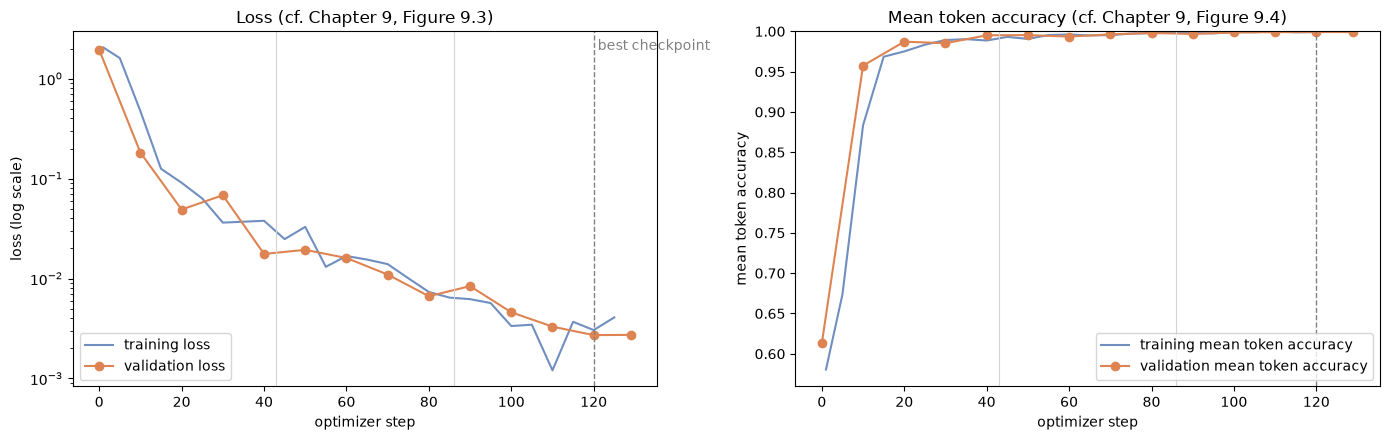

,before fine-tuning,after (best checkpoint)
training loss (mean of last 3 logs),NaN,0.0036
training mean token accuracy (last 3 logs),NaN,0.9991
validation loss,1.9470,0.0027
validation perplexity,7.0079,1.0027
validation mean token accuracy,0.6132,0.9991


Train-validation loss gap at the end: +0.0009 | accuracy gap: -0.0000


In [17]:
hist = pd.DataFrame(trainer.state.log_history)
train_log = hist[hist["loss"].notna()][["step", "epoch", "loss", "train_mean_token_accuracy", "learning_rate", "grad_norm"]]
eval_log = hist[hist["eval_loss"].notna() & (hist["step"] > 0)][["step", "eval_loss", "eval_mean_token_accuracy"]]
eval_log = eval_log.drop_duplicates("step", keep="first")
eval_log = pd.concat([pd.DataFrame([{"step": 0, "eval_loss": before["eval_loss"],
                                     "eval_mean_token_accuracy": before["eval_mean_token_accuracy"]}]), eval_log])

# OpenAI-style results file (Chapter 9)
results = (train_log.rename(columns={"loss": "train_loss"})
           .merge(eval_log.rename(columns={"eval_loss": "valid_loss", "eval_mean_token_accuracy": "valid_mean_token_accuracy"}),
                  on="step", how="outer").sort_values("step"))
results = results[["step", "epoch", "train_loss", "train_mean_token_accuracy", "valid_loss", "valid_mean_token_accuracy",
                   "learning_rate", "grad_norm"]]
results.to_csv("results.csv", index=False)
display(results.round({c: 4 for c in results.columns if c != "learning_rate"}).reset_index(drop=True))

best_step = int(trainer.state.best_model_checkpoint.split("-")[-1])
fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))
ax = axes[0]
ax.plot(train_log.step, train_log.loss, color="#4C72B0", alpha=0.8, label="training loss")
ax.plot(eval_log.step, eval_log.eval_loss, "o-", color="#DD8452", label="validation loss")
ax.axvline(best_step, color="gray", ls="--", lw=1); ax.text(best_step, ax.get_ylim()[1] * 0.9, " best checkpoint", color="gray")
ax.set_yscale("log"); ax.set_xlabel("optimizer step"); ax.set_ylabel("loss (log scale)")
ax.set_title("Loss (cf. Chapter 9, Figure 9.3)"); ax.legend()
ax = axes[1]
ax.plot(train_log.step, train_log.train_mean_token_accuracy, color="#4C72B0", alpha=0.8, label="training mean token accuracy")
ax.plot(eval_log.step, eval_log.eval_mean_token_accuracy, "o-", color="#DD8452", label="validation mean token accuracy")
ax.axvline(best_step, color="gray", ls="--", lw=1)
ax.set_xlabel("optimizer step"); ax.set_ylabel("mean token accuracy"); ax.set_ylim(None, 1.0)
ax.set_title("Mean token accuracy (cf. Chapter 9, Figure 9.4)"); ax.legend(loc="lower right")
for a in axes:
    for e in range(1, int(args.num_train_epochs)):
        a.axvline(e * steps_per_epoch, color="lightgray", lw=0.8)
plt.tight_layout(); plt.savefig("training_metrics.png", dpi=150); plt.show()

last_train = train_log.tail(3)
metrics_table = pd.DataFrame({
    "before fine-tuning": [None, None, before["eval_loss"], math.exp(before["eval_loss"]), before["eval_mean_token_accuracy"]],
    "after (best checkpoint)": [last_train.loss.mean(), last_train.train_mean_token_accuracy.mean(), after["eval_loss"],
                                math.exp(after["eval_loss"]), after["eval_mean_token_accuracy"]],
}, index=["training loss (mean of last 3 logs)", "training mean token accuracy (last 3 logs)", "validation loss",
          "validation perplexity", "validation mean token accuracy"])
display(metrics_table.round(4))
print(f"Train-validation loss gap at the end: {last_train.loss.mean() - after['eval_loss']:+.4f} | "
      f"accuracy gap: {last_train.train_mean_token_accuracy.mean() - after['eval_mean_token_accuracy']:+.4f}")

### Commentary

Read the way Chapter 9 describes it, this is a **good fit, not overfitting**.

- **Loss.** Training loss falls from 2.05 at the first step to about 0.004 at the end, and validation loss falls right alongside it, from 1.95 to 0.0027. The final gap is only +0.0009. Validation loss never climbs while training loss keeps falling, which is the overfitting signature the chapter warns about. There are a few small bumps (steps 30, 50, and 90) where validation loss ticks up slightly before falling again. That's the batch-to-batch noise the chapter says is normal.
- **Mean token accuracy.** Validation accuracy goes from 61.3% before training to 95.8% after only 10 steps, and 99.9% at the end. Training accuracy also finishes at 99.9%, so there's no train/validation gap either.
- **Perplexity** drops from 7.01 to 1.0027. In other words, the model is almost never unsure what the next token of a label should be.

Most of the learning happens in the first epoch. By step 20, half an epoch in, validation accuracy is already 98.7%, and epochs 2 and 3 polish the last 1%. My honest reading is that numbers this close to perfect say as much about my data as about the model. The labels come from templates, so once the model learns the template, almost every token is predictable. Chapter 9 makes the same point: higher token accuracy is expected "for simpler tasks or texts with predictable patterns" (Bahree, 2024, p. 264). These curves show the model learned my label *format*. They don't show it reads sigs *correctly*, which is what Step 7 tests.

## Step 7: Evaluating the fine-tuned model (Chapter 9, section 9.3.2)

Loss and token accuracy show the model learned to *predict the training format*, but Chapter 9 is clear that they aren't the whole story: a high token accuracy "does not reflect how well the model generalizes to new or unseen data" (Bahree, 2024, p. 264). For that the chapter recommends **task-specific evaluation**, **baseline benchmarking**, **a mix of quantitative metrics**, and **error analysis**. Here is how each one maps to my project:

| Chapter 9 | In this project |
|---|---|
| Baseline benchmarking | the same tests for the lookup table, the base 0.5B and 3B models, and the fine-tuned model |
| Task completion / accuracy | **critical errors** (my primary metric), correct-or-caught %, valid-output % |
| F1 score | precision, recall, and F1 for **flagging**, where "should this go to a pharmacist?" is the classification |
| Overlap metrics (BLEU, ROUGE) | BLEU and ROUGE-L of the patient sentence against the gold sentence on the held-out split |
| Perplexity | validation perplexity before vs. after training (Step 6) |
| Accuracy (factual) | field-level exact match for each of the structured JSON fields |
| Error analysis | every remaining critical error, grouped by type |
| Human evaluation / qualitative | my own read of sample outputs for relevance, coherence, accuracy, and fluency (the four criteria in Table 9.1) |

The fine-tuned model gets only the short `TRAIN_SYSTEM` prompt, with no rules and no examples, so everything it does right had to be learned from the training data.

In [18]:
del trainer.optimizer
model.eval(); model.config.use_cache = True
free_memory()
tok.padding_side = "left"
with stage("Evaluate fine-tuned model"):
    ft_df = evaluate_model("4. Fine-tuned 0.5B (short prompt)", model.to(INFER_DTYPE), tok,
                           lambda s: [{"role": "system", "content": TRAIN_SYSTEM}, {"role": "user", "content": s}])

all_results = pd.concat([baseline_df, ft_df], ignore_index=True)
all_results.to_csv("m3_all_results.csv", index=False)
summary = summarize(all_results.assign(run=all_results.test_set + " | " + all_results.experiment), by="run")
summary.to_csv("m3_summary.csv")
summary

4. Fine-tuned 0.5B (short prompt): 113 sigs in 22s | critical 6 | invalid 1
[stage] Evaluate fine-tuned model: 0.4 min


,inputs,valid_output_%,correct_or_caught_%,critical_errors,flag_recall_%,false_flag_%
run,,,,,,
held-out test | 1. Lookup table,85,100.0,78.8,18,0.0,0.0
M2 suite | 1. Lookup table,28,100.0,57.1,12,0.0,0.0
held-out test | 2. Base 0.5B + best prompt,85,100.0,20.0,41,52.9,39.7
M2 suite | 2. Base 0.5B + best prompt,28,96.4,28.6,9,75.0,50.0
held-out test | 3. Base 3B + best prompt,85,100.0,51.8,27,17.6,20.6
M2 suite | 3. Base 3B + best prompt,28,100.0,35.7,9,0.0,45.0
held-out test | 4. Fine-tuned 0.5B (short prompt),85,98.8,95.3,3,76.5,0.0
M2 suite | 4. Fine-tuned 0.5B (short prompt),28,100.0,85.7,3,87.5,5.0


### Commentary

**Yes, the fine-tuning worked, and by a wide margin on my primary metric.**

| | Held-out critical errors | M2 suite critical errors | M2 flag recall | M2 false flags |
|---|---|---|---|---|
| Lookup table | 18 | 12 | 0% | 0% |
| Base 0.5B + best prompt | 41 | 9 | 75% | 50% |
| Base 3B + best prompt | 27 | 9 | 0% | 45% |
| **Fine-tuned 0.5B** | **3** | **3** | **87.5%** | **5%** |

On the held-out split, the fine-tuned model gets 81 of 85 sigs correct or caught (95.3%). That's down from 41 critical errors before training to 3, with no false flags and one invalid reply. All 3 remaining critical errors are error-prone sigs it translated instead of flagging, and the invalid reply was on an error-prone sig too, so its flag recall there is 76.5% (13 of 17). I'll dig into those in Step 8. I don't put too much weight on the held-out split by itself, because those sigs come from the same generator the model trained on.

**The hand-written Milestone 2 suite is the result I care about most.** Critical errors drop from 9 (the same model before training) to 3. The model now catches 7 of the 8 error-prone inputs plus the typo and the nonsense string. The 3B model caught none of those 8 error-prone inputs. It also mostly stopped over-flagging: false flags drop from 50% to 5%, which is one sig (R6). This is the behavior my Milestone 2 conclusion said had to be *learned*: knowing when a sig isn't safe to translate. A model one-sixth the size of the 3B, with a one-sentence prompt, now does it far better than the 3B does with a full rules prompt and six examples.

### Flag F1, field accuracy, and overlap metrics

**Flagging as classification (F1).** The positive class is "should be flagged": the error-prone sigs plus the Milestone 2 typo and nonsense variants. R1 (`1 PO BID PRN x10d`) is left out because Milestone 2 accepts either answer for it. *Recall* is the safety number: a missed flag is a confidently wrong label. *Precision* is the workload number: a false flag costs the pharmacist time.

**Field-level exact match** compares each structured field with the gold label after light normalization (case, trailing punctuation, number words). This is only meaningful on the held-out split, where gold fields exist, and it's harsh on the base models: "2 times a day" is a mismatch with "twice daily" even though it's correct. That's why critical errors, not this table, are my primary metric.

**BLEU and ROUGE-L** measure word overlap between the predicted patient sentence and the gold sentence (Papineni et al., 2002; Lin, 2004). Chapter 9 lists them as standard overlap metrics and also warns that they don't capture whether a sentence is *correct*. One wrong number barely changes BLEU but can make a label dangerous.

In [19]:
import sacrebleu
from rouge_score import rouge_scorer
from sklearn.metrics import precision_recall_fscore_support

gold_by_id = {e["id"]: e["label"] for e in test_ex}
expect_by_key = {(s, c["id"]): c["expect_flag"] for s, cases in TEST_SETS.items() for c in cases}

def norm_field(v):
    if v is None or v == "" or v == []:
        return None
    s = str(v).lower().strip().rstrip(".")
    for w, d in NUMW.items():
        s = re.sub(rf"\b{d}\b", w, s)
    return re.sub(r"\s+", " ", s.replace("milliliters", "ml").replace("milliliter", "ml"))

FIELD_COLS = ["dose", "dose_form", "route", "frequency", "as_needed", "indication", "duration", "max_daily",
              "additional_instructions"]
scorer = rouge_scorer.RougeScorer(["rougeL"], use_stemmer=True)
rows = []
for name, g in all_results.groupby("experiment", sort=False):
    # ---- flag precision / recall / F1 over both test sets ----
    keep = [expect_by_key[(r.test_set, r.id)] is not None for r in g.itertuples()]
    gg = g[keep]
    y_true = [bool(expect_by_key[(r.test_set, r.id)]) for r in gg.itertuples()]
    p, r_, f1, _ = precision_recall_fscore_support(y_true, gg.flagged.tolist(), average="binary", zero_division=0)
    # ---- field exact match + BLEU/ROUGE on the held-out split ----
    h = g[g.test_set == "held-out test"]
    field_acc = {}
    for col in FIELD_COLS:
        ok = [isinstance(r.pred, dict) and norm_field(r.pred.get(col)) == norm_field(gold_by_id[r.id][col]) for r in h.itertuples()]
        field_acc[col] = 100 * np.mean(ok)
    preds = [(r.pred if isinstance(r.pred, dict) else {}).get("patient_instruction", "") or "" for r in h.itertuples()]
    refs = [gold_by_id[r.id]["patient_instruction"] for r in h.itertuples()]
    bleu = sacrebleu.corpus_bleu(preds, [refs]).score
    rougeL = 100 * np.mean([scorer.score(ref, pred)["rougeL"].fmeasure for ref, pred in zip(refs, preds)])
    rows.append({"experiment": name, "flag_precision": round(p, 3), "flag_recall": round(r_, 3), "flag_F1": round(f1, 3),
                 "all_fields_exact_%": round(100 * np.mean([all(isinstance(r.pred, dict) and norm_field(r.pred.get(c)) == norm_field(gold_by_id[r.id][c]) for c in FIELD_COLS) for r in h.itertuples()]), 1),
                 "BLEU": round(bleu, 1), "ROUGE-L": round(rougeL, 1),
                 **{f"{c}_%": round(v, 1) for c, v in field_acc.items()}})
extra_metrics = pd.DataFrame(rows).set_index("experiment")
extra_metrics.to_csv("m3_extra_metrics.csv")
display(extra_metrics[["flag_precision", "flag_recall", "flag_F1", "all_fields_exact_%", "BLEU", "ROUGE-L"]])
display(extra_metrics[[f"{c}_%" for c in FIELD_COLS]].rename(columns=lambda c: c[:-2]).T)

,flag_precision,flag_recall,flag_F1,all_fields_exact_%,BLEU,ROUGE-L
experiment,,,,,,
1. Lookup table,0.000,0.000,0.000,28.2,82.5,94.8
2. Base 0.5B + best prompt,0.288,0.556,0.380,1.2,39.7,61.9
3. Base 3B + best prompt,0.179,0.185,0.182,11.8,62.8,81.0
4. Fine-tuned 0.5B (short prompt),0.957,0.815,0.880,97.6,98.3,98.5


experiment,1. Lookup table,2. Base 0.5B + best prompt,3. Base 3B + best prompt,4. Fine-tuned 0.5B (short prompt)
dose,58.8,88.2,74.1,98.8
dose_form,96.5,22.4,51.8,98.8
route,96.5,64.7,81.2,97.6
frequency,82.4,25.9,43.5,98.8
as_needed,100.0,69.4,98.8,98.8
indication,98.8,71.8,97.6,98.8
duration,78.8,47.1,94.1,98.8
max_daily,94.1,84.7,95.3,98.8
additional_instructions,88.2,74.1,84.7,98.8


### Commentary

The F1 score tells the same story as the critical-error count. The fine-tuned model flags with **precision 0.957 and recall 0.815 (F1 = 0.880)**. It raised 23 flags and only one was unnecessary, and it flagged 22 of the 27 sigs that needed a pharmacist. The base 0.5B model's F1 is 0.380, the 3B model's is 0.182, and the lookup table's is 0 because it never flags. Recall is the number I most want to raise, since every missed flag is a potential bad label.

Field-level accuracy shows the model learned the structured fields, not just the sentence. On the held-out split, 97.6% of its labels match the gold label on all nine fields, compared with 28.2% for the lookup table and 1-12% for the base models. As I expected, this table is harsh on the base models because they choose their own wording. Most of the fine-tuned model's fields are at 98.8%; the one missing example in each column is the reply that wasn't valid JSON.

**BLEU (98.3) and ROUGE-L (98.5) are near the ceiling, but I don't read much into them.** The lookup table also scores high, 82.5 BLEU and 94.8 ROUGE-L, even though it makes 18 critical errors on the same sigs. A sentence that says "once daily" where it should have flagged `QD` overlaps almost perfectly with the correct sentence. That's exactly the limitation Chapter 9 warns about: overlap metrics measure wording, not correctness, and in a medication task one wrong word can be the whole difference.

## Step 8: Error analysis (Chapter 9)

Chapter 9 describes error analysis as looking at *where and why* the fine-tuned model still fails and sorting the mistakes into patterns, because the patterns tell you what data or training to change next. Below are (1) outcomes by sig type for every model on the held-out split, (2) every remaining critical error from the fine-tuned model, and (3) a side-by-side of the Milestone 2 suite, so I can see exactly which hand-written sigs changed.

In [20]:
FT, B05, B3, LK = "4. Fine-tuned 0.5B (short prompt)", "2. Base 0.5B + best prompt", "3. Base 3B + best prompt", "1. Lookup table"
held = all_results[all_results.test_set == "held-out test"]
by_type = (held.assign(ok=held.outcome.isin(["correct", "caught"]))
           .pivot_table(index=["category", "subtype"], columns="experiment", values="ok", aggfunc="mean") * 100).round(0)
by_type["n"] = held[held.experiment == FT].groupby(["category", "subtype"]).size()
print("Held-out split: % correct (or caught) by sig type")
display(by_type)

ft_crit = all_results[(all_results.experiment == FT) & all_results.critical]
print(f"\nFine-tuned model: {len(ft_crit)} critical errors")
display(ft_crit[["test_set", "id", "subtype", "sig", "patient_instruction", "outcome"]])

ft_other = all_results[(all_results.experiment == FT) & all_results.outcome.isin(["over-flagged", "invalid output"])]
print(f"Fine-tuned model: {len(ft_other)} non-critical failures (over-flagged or invalid)")
display(ft_other[["test_set", "id", "sig", "patient_instruction", "outcome"]])

m2 = all_results[all_results.test_set == "M2 suite"]
side = m2.pivot_table(index=["id", "sig"], columns="experiment", values="outcome", aggfunc="first")
side = side.reindex([c["id"] for c in M2_SUITE], level=0)
print("\nMilestone 2 suite, outcome by model:")
display(side)

Held-out split: % correct (or caught) by sig type


experiment                         1. Lookup table  2. Base 0.5B + best prompt  3. Base 3B + best prompt  4. Fine-tuned 0.5B (short prompt)   n
category    subtype                                                                                                                            
complex     loading dose                     100.0                         0.0                       0.0                              100.0   3
            range + daily max                100.0                         0.0                       0.0                              100.0   1
            split AM/PM                      100.0                         0.0                       0.0                              100.0   2
            taper                            100.0                         0.0                      50.0                              100.0   2
            two extra directions             100.0                         0.0                     100.0                              100.0   4
error-prone D/C                                0.0                       100.0                     100.0                              100.0   1
            OD/OS/OU                           0.0                        33.0                       0.0                               67.0   3
            QD                                 0.0                        75.0                       0.0                               50.0   4
            QOD                                0.0                       100.0                       0.0                              100.0   2
            TIW                                0.0                         0.0                       0.0                               50.0   2
            cc                                 0.0                        50.0                       0.0                              100.0   2
            conflicting frequency              0.0                       100.0                       0.0                              100.0   1
            missing frequency                  0.0                         0.0                     100.0                              100.0   2
routine     cap                              100.0                         0.0                      33.0                              100.0   3
            mg                                92.0                        25.0                      67.0                              100.0  12
            mg_inj                           100.0                       100.0                     100.0                              100.0   1
            supp                             100.0                         0.0                       0.0                              100.0   3
            tab                              100.0                        12.0                      84.0                              100.0  25
            units                            100.0                         8.0                      42.0                              100.0  12


Fine-tuned model: 6 critical errors


,test_set,id,subtype,sig,patient_instruction,outcome
350,held-out test,test-E011,QD,2 tabs po QD,Take 2 tablets by mouth once daily.,CRITICAL: guessed
356,held-out test,test-E017,TIW,2 tabs p.o. t.i.w.,Take 2 tablets by mouth three times a week.,CRITICAL: guessed
421,held-out test,test-E082,QD,1 cap p.o. QD,Take 1 capsule by mouth once daily.,CRITICAL: guessed
424,M2 suite,R1,routine,1 PO BID PRN x10d,Instill 1 drop in both eyes twice daily as needed for 10 days.,CRITICAL: wrong
446,M2 suite,C6-v1,complex,1 TAB SL Q5MIN PRN CP X3 DOSES MAX IN 15 MIN. CALL 911 IF UNRELIEVED,Place 1 tablet under the tongue every 5 minutes as needed for chest pain. Do not take more than 3 tablets per day.,CRITICAL: wrong
449,M2 suite,E1-v2,error-prone,1 TAB PO QD,Take 1 tablet by mouth once daily.,CRITICAL: guessed


Fine-tuned model: 2 non-critical failures (over-flagged or invalid)


,test_set,id,sig,patient_instruction,outcome
340,held-out test,test-E001,1 gtt o.d. qhs,,invalid output
429,M2 suite,R6,apply aa bid,Apply to the affected area twice daily.,over-flagged



Milestone 2 suite, outcome by model:


,experiment,1. Lookup table,2. Base 0.5B + best prompt,3. Base 3B + best prompt,4. Fine-tuned 0.5B (short prompt)
id,sig,,,,
R1,1 PO BID PRN x10d,correct,CRITICAL: wrong,flagged (acceptable),CRITICAL: wrong
R2,1 cap po tid x7d,correct,CRITICAL: wrong,correct,correct
R3,1 tab po daily,correct,over-flagged,correct,correct
R4,2 puffs inh q4-6h prn sob,correct,CRITICAL: wrong,over-flagged,correct
R5,5 ml po bid x10d,correct,correct,correct,correct
R6,apply aa bid,correct,over-flagged,over-flagged,over-flagged
C1,"1-2 tabs PO q4-6h PRN pain, max 8/day",correct,over-flagged,over-flagged,correct
C2,"2 tabs po on day 1, then 1 tab po daily on days 2-5",correct,over-flagged,over-flagged,correct
C3,1 tab po qam and 2 tabs po qpm,correct,over-flagged,CRITICAL: wrong,correct


In [25]:
# The Step 2 self-check found one scorer weakness: for meal-time frequencies ("once daily with dinner"),
# a damaged "twice daily with dinner" still passed. Re-score the held-out split with the "no conflicting
# frequency" rule applied to every frequency, and check whether any model's outcome changes.
def strict_case(c):
    c = dict(c)
    per_day = next((v[2] for v in FREQS.values() if v[1] == c["label"]["frequency"]), None)
    if per_day in PER_DAY_CONFLICTS:
        c["must_not"] = list(dict.fromkeys(c["must_not"] + PER_DAY_CONFLICTS[per_day]))
    return c

test_by_id = {c["id"]: c for c in test_ex}
changed = []
for r in all_results[all_results.test_set == "held-out test"].itertuples():
    new = score(strict_case(test_by_id[r.id]), r.pred if isinstance(r.pred, dict) else None)["outcome"]
    if new != r.outcome:
        changed.append((r.experiment, r.id, r.sig, r.outcome, new))
gold_fail = sum(score(strict_case(e), e["label"])["outcome"] != "correct" for e in examples if e["category"] != "error-prone")
print(f"Gold labels that fail the stricter rule: {gold_fail}")
print(f"Held-out outcomes that change under the stricter rule: {len(changed)}", changed[:5])

Gold labels that fail the stricter rule: 0
Held-out outcomes that change under the stricter rule: 0 []


### Commentary

On the held-out split, the fine-tuned model is at 100% on every routine and complex sig type. Its misses are all in three error-prone types: `QD` (2 of 4 caught), `TIW` (1 of 2), and `OD`/`OS`/`OU` (2 of 3). Across both test sets it has **six critical errors and two safe failures**, and they fall into clear patterns:

1. **Uppercase `QD` is read as "once daily" (3 critical: `2 tabs po QD`, `1 cap p.o. QD`, `1 TAB PO QD`).** Lowercase `qd` and dotted `q.d.` were caught every time. I checked the training set, and it explains this: only 7 training examples were `QD` sigs, and just one of them had `QD` in capitals (`1 supp pr QD`). Meanwhile 137 training sigs were written in ALL CAPS, and almost all of those were routine, like `1 TAB PO DAILY`. So to the model, capital letters plus a daily-sounding code looks safe. This is the surface-form problem from Milestone 2 Experiment 5, and the fix is more error-prone examples in every format, not just a few.
2. **Dotted `t.i.w.` translated as "three times a week" (1 critical).** The meaning is right, but TIW is exactly the kind of sig that must be flagged. The training examples with dotted `t.i.w.` all said "by mouth" rather than `p.o.`, so this specific combination was new.
3. **R1, `1 PO BID PRN x10d` → "Instill 1 drop in both eyes twice daily as needed for 10 days." (critical).** This is the sig from my Milestone 1 paper, and it has no dose form. Every training sig had a form or unit word (tab, cap, ml, mg, units, gtt, puffs), so the model never learned what to do when one is missing. My best guess is that it latched onto the short "1 ... bid" shape it mostly saw in eye-drop sigs (`1 gtt both eyes bid`), even ignoring the explicit `PO`. The right answer is a flag or "Take 1 by mouth," and my generator never produced a sig with a missing dose form. That's an easy data fix.
4. **C6-v1, the all-caps nitroglycerin sig → "...Do not take more than 3 tablets per day." (critical).** It dropped "call 911" entirely and turned "max in 15 minutes" into a daily limit. "Max 3 doses in 15 minutes" never appears in my MIMIC-based training data, so the model had nothing to copy.
5. **`1 gtt o.d. qhs` → invalid JSON (safe failure).** The model started a correct flag for `o.d.` but broke the JSON while writing it out, so the app would show nothing. It's safe, but it's a failure.
6. **R6, `apply aa bid` → flagged unnecessarily (safe failure).** The translation itself was right, but the model invented a reason for the flag (see Step 9). This one is ironic: my leak filter removed every generated `apply aa bid` because it exactly matched this test sig, and topical orders are rare in MIMIC, so the model saw very few short topical sigs.

Row by row against the base 0.5B model on the Milestone 2 suite: fine-tuning fixed 8 of its 9 critical errors (all but R1) and turned 9 of its 10 over-flagged sigs into correct translations. It introduced two new critical errors: C6-v1, which the base model had answered with invalid JSON, and `1 TAB PO QD`, which the base model had caught.

The stricter re-scoring cell above settles the scorer weakness I found in Step 2. With the "no conflicting frequency" rule applied to every frequency, all gold labels still pass and **no model's outcome changes**, so that gap didn't affect any of the numbers in this notebook.

## Step 9: Reading the outputs myself (Chapter 9, Table 9.1 criteria)

Automated scores can't judge whether a label *reads* well, so I read a sample of the fine-tuned model's patient sentences next to the base model's. I judge them on the four criteria in Chapter 9's Table 9.1: **relevance** (does it answer *this* sig?), **coherence** (does it make logical sense as one instruction?), **accuracy** (are the facts right?), and **fluency** (would a patient read it naturally?). The sample deliberately includes the hardest Milestone 2 sigs.

In [26]:
show_ids = ["R4", "R6", "C1", "C2", "C3", "C4", "C5", "C6", "E3", "E4", "C6-v1", "R3-v3"]
q = m2[m2.id.isin(show_ids) & m2.experiment.isin([B05, FT])]
qual = q.pivot_table(index=["id", "sig"], columns="experiment", values="patient_instruction", aggfunc="first")
qual = qual.reindex(show_ids, level=0)
with pd.option_context("display.max_colwidth", 200):
    display(qual)
    flags_ft = m2[(m2.experiment == FT) & m2.flagged][["id", "sig", "raw"]]
    flags_ft["flag"] = [((parse_label(r) or {}).get("flags") or [{}])[0].get("abbreviation", "") + ": " +
                        ((parse_label(r) or {}).get("flags") or [{}])[0].get("reason", "")[:110] for r in flags_ft.raw]
    print("\nFlags the fine-tuned model raised on the Milestone 2 suite:")
    display(flags_ft[["id", "sig", "flag"]])

,experiment,2. Base 0.5B + best prompt,4. Fine-tuned 0.5B (short prompt)
id,sig,,
R4,2 puffs inh q4-6h prn sob,Inhale 2 puffs every 4-6 hours as needed for sob. Do not exceed 4 puffs in 24 hours.,Inhale 2 puffs every 4 to 6 hours as needed for shortness of breath.
R6,apply aa bid,Apply a cream twice daily.,Apply to the affected area twice daily.
C1,"1-2 tabs PO q4-6h PRN pain, max 8/day",Take 1-2 tabs by mouth every 4-6 hours for 8 days.,Take 1 to 2 tablets by mouth every 4 to 6 hours as needed for pain. Do not take more than 8 tablets per day.
C2,"2 tabs po on day 1, then 1 tab po daily on days 2-5",Take 2 tabs by mouth on day 1 and 1 tab daily from days 2-5.,"Take 2 tablets by mouth on day 1, then take 1 tablet by mouth once daily on days 2 through 5."
C3,1 tab po qam and 2 tabs po qpm,Take 1 tablet by mouth every 2 hours and 2 tablets by mouth every 12 hours.,Take 1 tablet by mouth in the morning and 2 tablets by mouth in the evening.
C4,"4 tabs po daily x3d, then 3 tabs daily x3d, then 2 tabs daily x3d, then 1 tab daily x3d, then stop","Take 4 tabs daily for 3 days, then 3 tabs daily for 3 days, then 2 tabs daily for 3 days, then 1 tab daily for 3 days, then stop.","Take 4 tablets by mouth once daily for 3 days, then 3 tablets once daily for 3 days, then 2 tablets once daily for 3 days, then 1 tablet once daily for 3 days, then stop."
C5,"1 tab po bid w/ food, avoid grapefruit",Take 1 tablet by mouth every 24 hours with food and avoid grapefruit.,Take 1 tablet by mouth twice daily with food. Avoid grapefruit.
C6,"1 tab sl q5min prn cp, max 3 doses/15 min; call 911 if unrelieved",Take 1 tablet by mouth every 5 minutes as needed for chronic pain. Call 911 if the pain is not relieved after 3 doses within 15 minutes.,Place 1 tablet under the tongue every 5 minutes as needed for chest pain. Do not take more than 3 tablets per day. Call 911 if unrelieved.
E3,inject 10 U subq qhs,Subcutaneously inject 10 units every 12 hours for 72 hours.,Inject 10 units under the skin at bedtime.



Flags the fine-tuned model raised on the Milestone 2 suite:


,id,sig,flag
429,R6,apply aa bid,"AA: AA is on The Joint Commission ""Do Not Use"" list; it can be misread as A or B. Confirm which route."
436,E1,1 tab po qd,"QD: QD is on The Joint Commission ""Do Not Use"" list; it can be misread as QID (four times daily). Confirm the inte"
437,E2,1 tab po qod,"QOD: QOD is on The Joint Commission ""Do Not Use"" list; it can be misread as QD (daily) or QID. Confirm the intended"
438,E3,inject 10 U subq qhs,"U: U for units is on The Joint Commission ""Do Not Use"" list; it can be misread as 0 or 4 (10 U read as 100). Conf"
439,E4,1 gtt OD bid,OD: OD (once daily) is on the ISMP error-prone list; it can be misread as either 'every'. Confirm which frequency.
440,E5,take 1.0 mg po daily,"trailing zero: A trailing zero (e.g., 5.0 mg) is on The Joint Commission ""Do Not Use"" list; the decimal can be missed and the"
441,E6,1 tab po tiw,TIW: TIW is on the ISMP error-prone list; it can be misread as three times a day or twice a week. Confirm the inten
448,E1-v1,1 tab p.o. q.d.,"QD: QD is on The Joint Commission ""Do Not Use"" list; it can be misread as QID (four times daily). Confirm the inte"
450,R1-v3,1 PO BDI PRN x10d,BDI: BDI (both eyes) is on the ISMP error-prone list; it can be confused with both drops or eye drops. Confirm whic
451,R3-v3,qzz 3 tbs blah,(missing frequency): The sig does not say how often to take the medication; confirm with the prescriber.


### Commentary

Side by side, the fine-tuned model's labels are **relevant, coherent, and fluent** almost everywhere, and they read like the labels I print at work: verb first, then dose and form, route, frequency, the as-needed reason, duration, and a separate "Do not take more than..." sentence. The taper (C4), the loading dose (C2), the split dose (C3), and the dose range with a daily max (C1) are written exactly the way I'd want them. The base model never managed that. It wrote "every 2 hours" for "qam" (C3), "every 24 hours" for "bid" (C5), "chronic pain" for "cp" (C6), and "1 gram... orally" for an eye drop (E4).

Reading closely also turned up problems the automated scorer can't see, mostly under **accuracy**:

- **C6 is scored correct, but it isn't.** "Do not take more than 3 tablets per day" is wrong: the sig says 3 doses *in 15 minutes*, then call 911. My regex only checks that "3 tablets" and "911" appear, so it passes. For chest pain that's a meaningful error, and it's the clearest example in this notebook of Chapter 9's point that automated metrics need human review alongside them.
- **E4 is flagged correctly, but the reasoning behind it is wrong.** The best reading says "in the left eye" (OD is the *right* eye), and the flag reason calls OD "once daily." Since it's flagged, a pharmacist would catch it. But it shows the model learned *that* OD is dangerous much better than it learned *what* OD means.
- **Some flag reasons are made up.** R6's flag says "AA is on The Joint Commission 'Do Not Use' list; it can be misread as A or B." AA isn't on either list, and that misreading doesn't exist. The BDI typo is flagged, but the reason claims BDI means "both eyes." The flag is what stops a label from printing, so both outcomes are safe. But the reason is the first thing a pharmacist reads, and a confident fake reason could make them trust the model less, or worse, more. The model learned the *style* of a flag reason from 15 templates, not the facts behind it.
- **The nonsense string** (`qzz 3 tbs blah`) is flagged as "missing frequency," with a best reading of "Take 3 tablets by mouth." That's safe, but "this isn't readable" would be the better flag.

My overall judgment on the Table 9.1 criteria is that the fine-tuned model is far better than any baseline, but it isn't trustworthy without the pharmacist check. That's how I designed the system in Milestone 2 anyway: the model drafts and flags, and a pharmacist verifies.

## Step 10: Build log and saved artifacts

The tracked build process in one place: how long each stage took, the training configuration, and the files this notebook produced.

In [27]:
build = pd.DataFrame(BUILD_LOG)
build.loc[len(build)] = {"stage": "TOTAL", "minutes": round(build.minutes.sum(), 2)}
display(build)
display(pd.Series(HYPERPARAMS, name="value").to_frame())
print(f"Hardware: {torch.cuda.get_device_name(0)} ({GPU_GB:.1f} GB) | precision: {'bfloat16 mixed' if BF16 else 'float32'} | "
      f"peak training memory: {max(r['peak_gpu_gb'] for r in tracker.rows):.1f} GB")
print(f"Dataset: {len(train_ex)} train / {len(val_ex)} val / {len(test_ex)} test examples from "
      f"{len({e['order_id'] for e in examples if e.get('order_id') not in (None, -1)})} distinct MIMIC-IV orders")
for f in ["sig_train.jsonl", "sig_val.jsonl", "sig_test.jsonl", "results.csv", "training_metrics.png",
          "m3_all_results.csv", "m3_summary.csv", "m3_extra_metrics.csv", FT_DIR]:
    print(f"  {'OK ' if os.path.exists(f) else 'MISSING'} {f}")

,stage,minutes
0,Download MIMIC-IV demo tables,0.00
1,Map MIMIC orders to records,0.00
2,Generate training examples,0.00
3,Baseline 1: lookup table,0.00
4,"Baseline 2: base 0.5B, best M2 prompt",0.59
5,"Baseline 3: base 3B, best M2 prompt",1.49
6,Full fine-tune (training),3.26
7,Save fine-tuned model,0.02
8,Evaluate fine-tuned model,0.37
9,TOTAL,5.73


,value
learning_rate,0.00002
num_train_epochs,3
per_device_train_batch_size,8
gradient_accumulation_steps,2
warmup_steps,6
lr_scheduler_type,SchedulerType.LINEAR
bf16,True
gradient_checkpointing,True
eval_steps,10
seed,42


Hardware: NVIDIA GeForce RTX 5080 (17.1 GB) | precision: bfloat16 mixed | peak training memory: 12.2 GB
Dataset: 676 train / 84 val / 85 test examples from 644 distinct MIMIC-IV orders
  OK  sig_train.jsonl
  OK  sig_val.jsonl
  OK  sig_test.jsonl
  OK  results.csv
  OK  training_metrics.png
  OK  m3_all_results.csv
  OK  m3_summary.csv
  OK  m3_extra_metrics.csv
  OK  sig_translator_qwen05b_full_ft


## Conclusion: did the fine-tuning work?

**Yes.** Measured by my primary metric, critical errors, the fully fine-tuned 0.5B model is the safest system I've tested:

- **On my hand-written Milestone 2 suite it makes 3 critical errors.** With my best prompt, the same model makes 9, a model six times its size makes 9, and a lookup table makes 12. It catches 7 of the 8 error-prone abbreviations plus the typo and the nonsense input (the 3B model and the lookup table catch none of the 8 abbreviations), and it over-flags only one safe sig.
- **On the held-out split it makes 3 critical errors**, compared with 41 before training. It's 100% correct on every routine and complex sig type.
- **Training was clean by Chapter 9's standards.** Training and validation loss fell together to about 0.003 with almost no gap, mean token accuracy reached 99.9% on both, and validation loss was still at its lowest near the end, so there's no sign of overfitting.

What I'd caution, in my own words:

- **The remaining errors are all the dangerous kind,** a confident translation of a sig that should have been flagged, and they cluster: uppercase `QD` was missed all 3 times it appeared. That's a data problem (only one uppercase `QD` in training) rather than a model-size problem, and it's fixable.
- **The held-out numbers flatter the model.** The test split shares a generator and a label template with the training data, so the honest number is the hand-written suite, and that suite is only 28 sigs.
- **The results move between runs.** My first complete run made 0 and 2 critical errors, and the rerun shown here made 3 and 3. That's the same code, seed, and data, with only GPU nondeterminism changing. So a difference of one or two errors isn't meaningful, and I'd need several runs to report a fair average.
- **The data has blind spots I can now name:** no sigs missing a dose form (R1), no "max N doses in M minutes" pattern (C6), very few topical, inhaler, and eye-drop sigs, no ear drops, and too few error-prone examples written in every format. That's a direct consequence of building on hospital data from 100 patients.
- **Neither the scorer nor the flag reasons can be fully trusted.** The scorer checks that facts appear, not that they're attached to the right thing, and that let one wrong daily maximum (C6) through. The model sometimes invents a plausible-sounding reason for a flag. Only reading the outputs myself caught both problems.

Overall, fine-tuning did what prompting couldn't. It taught a small model the *behavior* of stopping to flag, not just the vocabulary, with a one-sentence prompt and on hardware I own. And because the finished model is only about 2 GB, it can run locally, so prescription text never has to leave the pharmacy. It's not ready to print labels on its own, but it was never meant to: it's a drafting and flagging tool, and a pharmacist always verifies.

### What's next

1. **Fix the data gaps from the error analysis.** Write every error-prone abbreviation in every format (lowercase, ALL CAPS, dotted, mixed), and add sigs with no dose form (the correct answer is a flag, or a translation that doesn't invent a form), "max N doses in M minutes" sigs, ear drops (`AD`/`AS`/`AU`), and more topical, inhaler, and eye-drop examples. Then retrain and re-check uppercase `QD`, R1, C6-v1, and R6.
2. **Teach correct flag reasons.** Give each abbreviation its own clearly different reason examples, and add a check that the reason names a real ISMP or Joint Commission entry, so the model can't invent one.
3. **Make the scorer stricter.** Before calling a translation correct, check that each number is attached to the right unit and time window (3 doses *per 15 minutes*, not per day).
4. **Report averages, not single runs.** Train with 3 different seeds and report the mean and range of critical errors, since this milestone showed that one run can differ from the next.
5. **Build a bigger independent test set and the app.** Write 100+ hand-written sigs, ideally de-identified real ones from work if I can get approval. Then load the saved model (`sig_translator_qwen05b_full_ft`) into the Streamlit app from my proposal: a flagged sig shows the flag and the best reading for the pharmacist, and nothing flagged ever prints automatically.

## References

Bahree, A. (2024). *Generative AI in action*. Manning Publications.

Institute for Safe Medication Practices. (2021). *ISMP list of error-prone abbreviations, symbols, and dose designations*. https://www.ismp.org

Johnson, A., Bulgarelli, L., Pollard, T., Horng, S., Celi, L. A., & Mark, R. (2023). *MIMIC-IV Clinical Database Demo* (version 2.2). PhysioNet. https://doi.org/10.13026/dp1f-ex47

Li, J., Lester, C., Zhao, X., Ding, Y., Jiang, Y., & Vydiswaran, V. G. V. (2020). PharmMT: A neural machine translation approach to simplify prescription directions. In *Findings of the Association for Computational Linguistics: EMNLP 2020* (pp. 2785–2796). Association for Computational Linguistics.

Lin, C.-Y. (2004). ROUGE: A package for automatic evaluation of summaries. In *Text Summarization Branches Out* (pp. 74–81). Association for Computational Linguistics.

Pais, C., Liu, J., Voigt, R., Gupta, V., Wade, E., & Bayati, M. (2024). Large language models for preventing medication direction errors in online pharmacies. *Nature Medicine, 30*(6), 1574–1582.

Papineni, K., Roukos, S., Ward, T., & Zhu, W.-J. (2002). BLEU: A method for automatic evaluation of machine translation. In *Proceedings of the 40th Annual Meeting of the Association for Computational Linguistics* (pp. 311–318).

Qwen. (2024). *Qwen2.5-0.5B-Instruct* [Model card]. Hugging Face. https://huggingface.co/Qwen/Qwen2.5-0.5B-Instruct

The Joint Commission. (2023). *Do not use list*. https://www.jointcommission.org

Wolf, T., Debut, L., Sanh, V., Chaumond, J., Delangue, C., Moi, A., ... Rush, A. M. (2020). Transformers: State-of-the-art natural language processing. In *Proceedings of the 2020 Conference on Empirical Methods in Natural Language Processing: System Demonstrations* (pp. 38–45).